# 5 — Neural Network Models for Volatility Prediction (Unified & Aligned Supplement)

**Question.** Does the wording of a company's Item 7 (Management's Discussion and Analysis) predict its share-price volatility over the next 12 months beyond what last year's volatility already tells us—and how do **architecture** (additive residual vs. gated interaction vs. chunk attention), **text representation** (Bag-of-Words TF-IDF vs. FinBERT), **loss function** (MSE vs. Huber), **target centering** (pooled vs. within-year joint), and **data/resource scaling** affect performance?

### What This Aligned Notebook Covers
This self-contained notebook harmonizes all neural-network experiments with `02-Linear-models.ipynb`, `02b-Joint-ridge.ipynb`, `03b-Attention-refit.ipynb`, `03c-Joint-attention.ipynb`, and `04b-Joint-second-encoder.ipynb`:

1. **Exact Split & Feature Parity (Section 5.2–5.4):** Exact alignment with `splits.csv` and `alex-02-ridge-results.csv`, explicit **Item 7-only** FinBERT slicing (`data.pkl['X'][:, 768:]`, 768 dims), optional EDGAR text enforcement (`REQUIRE_EDGAR`), and leakage-free per-split TF-IDF and within-year FinBERT standardization.
2. **Exact Seed-Count Parity & Single-Seed Reporting (Section 5.1 & 5.8):** Runs **5 seeds** (`SEEDS = [0, 1, 2, 3, 4]`) matching `03b`/`03c`/`04`/`04b`, and reports both **single-seed means** (directly comparable to `03b`/`03c`/`04`/`04b`) and **5-seed ensembles**.
3. **Pooled & Within-Year Joint Architectures (Section 5.5 & 5.7):**
   - **`ResidualTextNet`:** Single-hidden-layer additive residual MLP with isolated `AdamW` weight decay (exempting skip and biases) and full-window refitting.
   - **`GatedInteractionMLP`:** Concatenates hidden text features with prior volatility $z_{\text{before}}$ and modulates the text residual via a learned sigmoid gate $g(\mathbf{x}, z_{\text{before}}) \in (0, 1)$.
   - **Within-Year Joint Variants:** Demeans target, prior volatility, and FinBERT features by filing year, initializes the unpenalized skip slope at the no-text within-year slope $\gamma_0$, and centers test predictions on the straight line's level (`level_shift == 0.0`) for pure spread comparison against `02b` and `03c`.
   - **`FinBERTAttentionNet` (optional when chunk embeddings are present):** Masked additive attention-pooling over frozen 512-token FinBERT chunks + gated residual head, paired with a uniform mean-pooling ablation.
4. **Zero-Lookahead Validation Sweep (Section 5.6):** Tunes `(HIDDEN, DROPOUT, WEIGHT_DECAY)` and Huber $\delta$ strictly on the earliest `strict` validation year (`1999`, test year `2001`), eliminating cross-window look-ahead.
5. **1,000× Scaling & Parallelism Benchmark (Section 5.9):** Learning curve, sparse-per-batch vs. pre-dense speedup, CPU strong scaling (`1–8` threads), and stateless Map-only `HashingVectorizer` vs. Map-Reduce `CountVectorizer + TF-IDF`.

## 5.1 — Setup, Imports & Configuration

In [1]:
import gc
import gzip
import json
import os
import pickle
import sys
import tarfile
import time
import urllib.request
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer, HashingVectorizer, TfidfTransformer
from sklearn.linear_model import Ridge
import torch
from torch import nn

ROOT = Path("..")                              # notebook lives one level below repo root
PROCESSED = ROOT / "data" / "processed"
OUTPUT = ROOT / "data" / "output"
BOW_DIR = PROCESSED / "bow"
BOW_DIR.mkdir(parents=True, exist_ok=True)
kogan_dir = ROOT / "data" / "raw" / "kogan"
edgar_dir = PROCESSED / "edgar_matched"
KOGAN_URL = "https://www.cs.cmu.edu/~ark/10K/data/"

sys.path.insert(0, str(ROOT / "Alex"))         # shared scoring.py from 02-Linear-models
import scoring

# --- split, text source & display config ---------------------------------------------------------
MAIN_WINDOW = "paper"
REQUIRE_EDGAR = False                          # set True to require EDGAR Item 7 parity with 04 / 05b

# --- optional FinBERT overrides (leave None for automatic Item 7 slicing from data.pkl) ----------
FINBERT_DOC_PATH = None                        # e.g. PROCESSED / "finbert_item7.npy"
FINBERT_DOC_KEY = None                         # e.g. key inside data.pkl
CHUNK_EMB_PATH = PROCESSED / "finbert_item7_chunks.npz"
EXTRACT_CHUNKS_IF_MISSING = False              # set True on GPU/Colab to extract 512-token FinBERT chunks
MAX_CHUNKS = 16
FINBERT_MODEL_NAME = "ProsusAI/finbert"

# --- text & ridge features -----------------------------------------------------------------------
N_WORDS = 5000
MIN_DF = 50
TOKEN = r"(?u)\b[a-z]{2,}\b"
ALPHAS = [0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]

# --- default network hyperparameters (updated by zero-lookahead sweep in Section 5.6) ------------
HIDDEN = 16
ATTN_DIM = 64
DROPOUT = 0.5
LR = 1e-3
WEIGHT_DECAY = 5e-2
BATCH = 256
MAX_EPOCHS = 40
PATIENCE = 5
HUBER_DELTA = 1.0
SEEDS = [0, 1, 2, 3, 4]                        # exact 5-seed parity with 03b, 03c, 04, and 04b
VERY_LOW = -5.0                                # takeover-type reports, as in 04-Volatility-Checking

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device} | PyTorch CPU threads: {torch.get_num_threads()} / {os.cpu_count()} logical cores")
print(f"Seeds ({len(SEEDS)}): {SEEDS}")

Using device: cpu | PyTorch CPU threads: 8 / 16 logical cores
Seeds (5): [0, 1, 2, 3, 4]


## 5.2 — Reports, Split Verification & Item 7 FinBERT Loaders

Loads `data.pkl` via `scoring.frame`, checks exact split alignment with `splits.csv` and `alex-02-ridge-results.csv`, and explicitly slices **Item 7 only** (`data.pkl['X'][:, 768:]`, 768 dims) so document-level FinBERT inputs match `02`, `02b`, `03b`, and `03c`.

In [2]:
with open(PROCESSED / "data.pkl", "rb") as f:
    d = pickle.load(f)
df = scoring.frame(d)
y = df["logvol_after"].to_numpy()
prev = df["logvol_before"].to_numpy()
year_arr = df["year"].to_numpy()
keys = df["key"].tolist()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

def as_mask(m):
    m = np.asarray(m)
    if m.dtype == bool:
        return m
    out = np.zeros(len(df), dtype=bool)
    out[m] = True
    return out

# --- Item 7 text source metadata -----------------------------------------------------------------
meta = pd.read_csv(PROCESSED / "dataset.csv", parse_dates=["date"]).drop(columns="item7_source", errors="ignore")
assert meta["key"].is_unique, "key must identify one report"
src_file = PROCESSED / "item7_source.csv"
USE_EDGAR = src_file.exists() and edgar_dir.exists() and any(edgar_dir.glob("*.jsonl.gz"))
if REQUIRE_EDGAR:
    assert USE_EDGAR, "REQUIRE_EDGAR=True but data/processed/item7_source.csv or edgar_matched/ is missing."
TEXT_TAG = "edgar" if USE_EDGAR else "kogan"
if USE_EDGAR:
    meta = meta.merge(pd.read_csv(src_file)[["key", "item7_source"]], on="key", how="inner")
    assert not meta.duplicated(["cik", "year"]).any(), "company + year must identify one report"
else:
    meta["item7_source"] = "kogan"

data = df[["key"]].merge(meta, on="key", how="left", validate="one_to_one")
missing = data["item7_source"].isna()
assert not missing.any(), f"{int(missing.sum())} reports in data.pkl have no Item 7 source"
assert (data["year"].to_numpy() == year_arr).all(), "filing years differ between data.pkl and dataset.csv"
assert np.allclose(data["logvol_after"], y) and np.allclose(data["logvol_before"], prev), "labels differ"
print("Item 7 source:", data["item7_source"].value_counts().to_dict(),
      "(EDGAR rule from 03)" if USE_EDGAR else "(Kogan only: item7_source.csv / edgar_matched not found)")

# --- Item 7 FinBERT embedding loader (explicitly slices cols 768:1536 from data.pkl['X']) --------
def load_finbert_doc(d_obj, n_rows, processed_dir, explicit_path=None, explicit_key=None):
    def _extract_2d(arr):
        try:
            arr = np.asarray(arr)
        except (ValueError, TypeError):
            return None
        if arr.ndim == 2 and arr.shape[0] == n_rows and arr.shape[1] >= 64 and np.issubdtype(arr.dtype, np.number):
            return arr.astype(np.float32)
        return None

    if explicit_path is not None:
        p = Path(explicit_path)
        if p.exists() and p.suffix == ".npy":
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
        elif p.exists() and p.suffix == ".npz":
            z = np.load(p)
            for k in z.files:
                emb = _extract_2d(z[k])
                if emb is not None:
                    return emb, f"file:{p.name}[{k}]"

    if explicit_key is not None and isinstance(d_obj, dict) and explicit_key in d_obj:
        emb = _extract_2d(d_obj[explicit_key])
        if emb is not None:
            return emb, f"data.pkl[{explicit_key!r}]"

    # Standard handover file: X has Item 1 in cols 0:768 and Item 7 in cols 768:1536
    if isinstance(d_obj, dict) and "X" in d_obj:
        arr = _extract_2d(d_obj["X"])
        if arr is not None and arr.shape[1] == 1536:
            return arr[:, 768:].copy(), "data.pkl['X'][:, 768:] (Item 7 only)"
        if arr is not None:
            return arr, "data.pkl['X']"

    for pat in ["*finbert*7*.npy", "*item7*.npy", "*finbert*.npy", "*emb*.npy"]:
        for p in sorted(processed_dir.glob(pat)):
            emb = _extract_2d(np.load(p))
            if emb is not None:
                return emb, f"file:{p.name}"
    return None, None

X_FINBERT_DOC, FINBERT_DOC_SRC = load_finbert_doc(d, len(df), PROCESSED, FINBERT_DOC_PATH, FINBERT_DOC_KEY)
if X_FINBERT_DOC is not None:
    print(f"Loaded document-level FinBERT embeddings: shape={X_FINBERT_DOC.shape} from {FINBERT_DOC_SRC}")
else:
    avail = list(d.keys()) if isinstance(d, dict) else type(d).__name__
    print(f"Document-level FinBERT not auto-detected (data.pkl keys: {avail}). Set FINBERT_DOC_KEY/PATH to enable.")

27,142 reports, 1996-2006
Item 7 source: {'kogan': 27142} (Kogan only: item7_source.csv / edgar_matched not found)
Loaded document-level FinBERT embeddings: shape=(27142, 768) from data.pkl['X'][:, 768:] (Item 7 only)


In [3]:
# Split table and alignment verification with splits.csv and alex-02-ridge-results.csv
rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = (as_mask(m) for m in scoring.masks(df, T, window))
        ty = sorted(set(year_arr[train]))
        rows.append({"window": window, "test_year": T, "train_years": f"{ty[0]}-{ty[-1]}",
                     "validate_year": ty[-1], "train_reports": int(train.sum()), "test_reports": int(test.sum())})
split_table = pd.DataFrame(rows)

shared = pd.read_csv(OUTPUT / "splits.csv")
for r in shared.itertuples():
    train, _ = scoring.masks(df, r.test_year, r.window)
    assert as_mask(train).sum() == r.train_reports
assert set(shared.window) == set(scoring.WINDOWS)
print("Windows match data/output/splits.csv.")

copy_vs_line = scoring.evaluate(df, scoring.predict_copy, name="copy last year")
alex_file = OUTPUT / "alex-02-ridge-results.csv"
if alex_file.exists():
    alex = pd.read_csv(alex_file)
    keys_ = ["window", "test_year"]
    theirs = alex[alex.model == "copy last year"].set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    ours = copy_vs_line.set_index(keys_)[["test_reports", "mse", "baseline_mse"]].sort_index()
    pd.testing.assert_frame_equal(ours, theirs, check_dtype=False)
    print("Exact match on test reports, copy-last-year MSE, and straight-line MSE with 02.")
else:
    alex = None
    print(f"{alex_file.name} not found: only splits.csv verifies alignment with 02.")

display(split_table)

Windows match data/output/splits.csv.
Exact match on test reports, copy-last-year MSE, and straight-line MSE with 02.


,window,test_year,train_years,validate_year,train_reports,test_reports
0,paper,2001,1996-2000,2000,9747,2299
1,paper,2002,1997-2001,2001,10788,2587
2,paper,2003,1998-2002,2002,11399,3217
3,paper,2004,1999-2003,2003,12474,3168
4,paper,2005,2000-2004,2004,13422,3121
5,paper,2006,2001-2005,2005,14392,3003
6,strict,2001,1996-1999,1999,7596,2299
7,strict,2002,1997-2000,2000,8489,2587
8,strict,2003,1998-2001,2001,8812,3217
9,strict,2004,1999-2002,2002,9257,3168


In [4]:
def annual(logvol):
    return np.exp(logvol) * np.sqrt(252)

by_year = df.groupby("year").agg(
    reports=("key", "size"),
    typical_vol_before=("logvol_before", lambda v: annual(v.mean())),
    typical_vol_after=("logvol_after", lambda v: annual(v.mean())),
    corr_before_after=("logvol_before", lambda v: np.corrcoef(v, df.loc[v.index, "logvol_after"])[0, 1]),
)
by_year.style.format({"typical_vol_before": "{:.0%}", "typical_vol_after": "{:.0%}", "corr_before_after": "{:.2f}"})

,reports,typical_vol_before,typical_vol_after,corr_before_after
year,,,,
1996,1258,52%,51%,0.87
1997,1976,53%,55%,0.83
1998,2142,54%,69%,0.77
1999,2220,67%,72%,0.80
2000,2151,69%,75%,0.80
2001,2299,76%,65%,0.82
2002,2587,64%,62%,0.81
2003,3217,57%,46%,0.83
2004,3168,44%,39%,0.83


## 5.3 — Text to Word Counts & Optional FinBERT Chunk Loader

Candidate word counts (`min_df = 50`, English stop words removed) are computed once and cached to `data/processed/bow/`. If pre-extracted 512-token FinBERT chunk embeddings exist at `data/processed/finbert_item7_chunks.npz` (or `EXTRACT_CHUNKS_IF_MISSING = True` on a GPU), they are also loaded here for `FinBERTAttentionNet`.

In [5]:
def kogan_file(year):
    f = kogan_dir / f"{year}.tok.tgz"
    if not f.exists():
        kogan_dir.mkdir(parents=True, exist_ok=True)
        print("downloading", f.name)
        urllib.request.urlretrieve(KOGAN_URL + f.name, f)
    return f

def load_year_texts(year):
    rows = data[data["year"] == year]
    want_edgar = {(int(r.cik), int(r.year)): r.key for r in rows.itertuples() if r.item7_source == "edgar"}
    want_kogan = {r.key for r in rows.itertuples() if r.item7_source == "kogan"}
    texts = {}
    if want_edgar:
        with gzip.open(edgar_dir / f"{year}.jsonl.gz", "rt") as f:
            for line in f:
                rec = json.loads(line)
                key = want_edgar.get((int(rec["cik"]), int(rec["year"])))
                if key is not None:
                    texts[key] = rec["section_7"]
    if want_kogan:
        with tarfile.open(kogan_file(year)) as tar:
            for m in tar:
                if m.isfile():
                    key = Path(m.name).name.split(".")[0]
                    if key in want_kogan:
                        texts[key] = tar.extractfile(m).read().decode("utf-8", "replace")
    missing = set(rows["key"]) - set(texts)
    assert not missing, f"{year}: no text found for {len(missing)} reports, e.g. {sorted(missing)[:2]}"
    return [texts[k] for k in rows["key"]]

years_sorted = sorted(int(v) for v in np.unique(year_arr))
order = np.concatenate([np.flatnonzero(year_arr == yr) for yr in years_sorted])

cache_npz, cache_json = BOW_DIR / f"candidates_{TEXT_TAG}.npz", BOW_DIR / f"candidates_{TEXT_TAG}.json"
cached = None
if cache_npz.exists() and cache_json.exists():
    cached = json.loads(cache_json.read_text())
    if cached["keys"] != keys:
        cached = None
        print("saved word counts are for a different set of reports: counting again")
if cached is not None:
    X_counts = sp.load_npz(cache_npz).tocsr()
    vocab, timings = cached["vocab"], cached["timings"]
    print("loaded saved word counts")
else:
    def all_texts():
        for yr in years_sorted:
            yield from load_year_texts(yr)
    t0 = time.perf_counter()
    vec = CountVectorizer(min_df=MIN_DF, stop_words="english", token_pattern=TOKEN, dtype=np.int32)
    X_sorted = vec.fit_transform(all_texts()).tocsr()
    X_counts = X_sorted[np.argsort(order)]
    timings = {"count_seconds": time.perf_counter() - t0, "n_reports": int(X_counts.shape[0])}
    vocab = [str(w) for w in vec.get_feature_names_out()]
    sp.save_npz(cache_npz, X_counts)
    cache_json.write_text(json.dumps({"keys": keys, "vocab": vocab, "timings": timings}))

assert X_counts.shape == (len(df), len(vocab)), "row order must match `df`"
vocab = np.array(vocab)
print("count matrix (reports x candidate words):", X_counts.shape, "| timings:", {k: round(v, 1) for k, v in timings.items()})

# --- Optional FinBERT chunk embeddings loader / GPU extractor ------------------------------------
def extract_and_save_finbert_chunks(out_path, max_chunks=MAX_CHUNKS):
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(FINBERT_MODEL_NAME)
    enc = AutoModel.from_pretrained(FINBERT_MODEL_NAME).to(device)
    enc.eval()

    emb_arr = np.zeros((len(df), max_chunks, 768), dtype=np.float16)
    mask_arr = np.zeros((len(df), max_chunks), dtype=bool)
    for yr in years_sorted:
        yr_idx = np.flatnonzero(year_arr == yr)
        yr_texts = load_year_texts(yr)
        t0 = time.perf_counter()
        for row_idx, txt in zip(yr_idx, yr_texts):
            ids = tok(txt, add_special_tokens=False, truncation=False)["input_ids"]
            chunks_ids = [ids[i:i + 510] for i in range(0, max(1, len(ids)), 510)][:max_chunks]
            n_c = len(chunks_ids)
            seqs = [[tok.cls_token_id] + c + [tok.sep_token_id] for c in chunks_ids]
            max_len = max(len(s) for s in seqs)
            input_ids = torch.full((n_c, max_len), tok.pad_token_id, dtype=torch.long, device=device)
            attn_mask = torch.zeros((n_c, max_len), dtype=torch.long, device=device)
            for k, s in enumerate(seqs):
                input_ids[k, :len(s)] = torch.tensor(s, dtype=torch.long, device=device)
                attn_mask[k, :len(s)] = 1
            with torch.no_grad():
                out = enc(input_ids=input_ids, attention_mask=attn_mask).last_hidden_state
                m = attn_mask.unsqueeze(-1).float()
                pooled = (out * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
            emb_arr[row_idx, :n_c] = pooled.cpu().numpy().astype(np.float16)
            mask_arr[row_idx, :n_c] = True
        print(f"Extracted {yr}: {len(yr_idx):,} reports in {time.perf_counter() - t0:.1f}s")
    np.savez_compressed(out_path, embeddings=emb_arr, mask=mask_arr, keys=np.array(keys))
    return emb_arr, mask_arr

X_CHUNKS, CHUNK_MASK = None, None
if CHUNK_EMB_PATH.exists():
    z = np.load(CHUNK_EMB_PATH, allow_pickle=True)
    X_CHUNKS, CHUNK_MASK = z["embeddings"], z["mask"].astype(bool)
    if "keys" in z.files:
        assert list(z["keys"]) == keys, "Chunk keys do not match data.pkl!"
    print(f"Loaded FinBERT chunks: {X_CHUNKS.shape}, avg valid chunks/report={CHUNK_MASK.sum(axis=1).mean():.2f}")
elif EXTRACT_CHUNKS_IF_MISSING:
    X_CHUNKS, CHUNK_MASK = extract_and_save_finbert_chunks(CHUNK_EMB_PATH)
else:
    print(f"Chunk embeddings not found at {CHUNK_EMB_PATH} (skipping chunk-attention; set EXTRACT_CHUNKS_IF_MISSING=True on GPU to build).")

loaded saved word counts
count matrix (reports x candidate words): (27142, 15344) | timings: {'count_seconds': 91.2, 'n_reports': 27142}
Chunk embeddings not found at ..\data\processed\finbert_item7_chunks.npz (skipping chunk-attention; set EXTRACT_CHUNKS_IF_MISSING=True on GPU to build).


## 5.4 — Leakage-Free Features, Within-Year Targets & Expanded Ridge Baseline

All vocabulary selection, sublinear TF-IDF weighting, FinBERT z-scoring, within-year demeaning, and target standardization are fitted strictly on `fit_idx` during tuning/early stopping (`X_tune`) and refitted on `tr_idx` for final test evaluation (`X_full`). Within-year joint targets and slopes match `02b-Joint-ridge.ipynb` and `03c-Joint-attention.ipynb`.

In [6]:
def mse(a, b):
    return float(np.mean((np.asarray(a) - np.asarray(b)) ** 2))

def split_key(train, test):
    return (tuple(sorted(int(v) for v in set(year_arr[as_mask(train)]))), int(year_arr[as_mask(test)][0]))

def build_features(fit_mask, transform_mask):
    fit_idx = np.flatnonzero(fit_mask)
    counts_fit = X_counts[fit_idx]
    in_reports = np.asarray((counts_fit > 0).sum(axis=0)).ravel()
    total = np.asarray(counts_fit.sum(axis=0)).ravel()
    eligible = np.flatnonzero(in_reports >= MIN_DF)
    cols = np.sort(eligible[np.argsort(-total[eligible], kind="stable")[:N_WORDS]])

    rows = np.flatnonzero(fit_mask | transform_mask)
    tfidf = TfidfTransformer(sublinear_tf=True).fit(counts_fit[:, cols])
    X = tfidf.transform(X_counts[rows][:, cols]).astype(np.float32).tocsr()
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[rows] = np.arange(len(rows))
    return X, pos, cols, tfidf

def demean_by_year(values, idx):
    out = np.zeros(len(df), dtype=np.float32)
    for yr in np.unique(year_arr[idx]):
        m = idx[year_arr[idx] == yr]
        out[m] = (values[m] - values[m].mean()).astype(np.float32)
    return out

def demean_dense_by_year(X_all, idx):
    """Remove each year's own mean from a 2D feature matrix over rows `idx`."""
    out = X_all.copy()
    for yr in np.unique(year_arr[idx]):
        m = idx[year_arr[idx] == yr]
        out[m] = out[m] - out[m].mean(axis=0, keepdims=True)
    return out

def standardize_dense(X_all, fit_idx, eval_rows):
    mu = X_all[fit_idx].mean(axis=0, keepdims=True)
    sd = X_all[fit_idx].std(axis=0, keepdims=True) + 1e-6
    X_sub = ((X_all[eval_rows] - mu) / sd).astype(np.float32)
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[eval_rows] = np.arange(len(eval_rows))
    return X_sub, pos

def chunk_norm_stats(chunks_all, mask_all, fit_idx):
    valid = chunks_all[fit_idx][mask_all[fit_idx]].astype(np.float32)
    mu = valid.mean(axis=0, keepdims=True)
    sd = valid.std(axis=0, keepdims=True) + 1e-6
    return torch.from_numpy(mu).to(device), torch.from_numpy(sd).to(device)

def make_split(train, test):
    train, test = as_mask(train), as_mask(test)
    assert len(set(year_arr[test])) == 1, "one test year at a time"
    years = sorted(int(v) for v in set(year_arr[train]))
    val_year = years[-1]

    fit_mask = train & (year_arr != val_year)
    val_mask = train & (year_arr == val_year)
    tr_idx, te_idx = np.flatnonzero(train), np.flatnonzero(test)
    fit_idx, val_idx = np.flatnonzero(fit_mask), np.flatnonzero(val_mask)

    X_tune, pos_tune, cols_tune, tfidf_tune = build_features(fit_mask, val_mask)
    X_full, pos_full, cols_full, tfidf_full = build_features(train, test)
    X_te_nr = tfidf_tune.transform(X_counts[te_idx][:, cols_tune]).astype(np.float32)
    pos_te_nr = np.full(len(df), -1, dtype=np.int64)
    pos_te_nr[te_idx] = np.arange(len(te_idx))

    mu_fit, sd_fit = float(y[fit_idx].mean()), float(y[fit_idx].std())
    mu_full, sd_full = float(y[tr_idx].mean()), float(y[tr_idx].std())

    a_all, b_all = scoring.fit_line(df, train)
    a_fit, b_fit = scoring.fit_line(df, fit_mask)
    line_all, line_fit = a_all + b_all * prev, a_fit + b_fit * prev

    # Two-step within-year residuals
    wy_resid_tune = demean_by_year(y - line_fit, fit_idx)
    wy_resid_tune[val_idx] = demean_by_year(y - line_fit, val_idx)[val_idx]
    wy_resid_all = demean_by_year(y - line_all, tr_idx)

    # Joint within-year target and prior volatility (matching 02b / 03c / 05b)
    y_wy_tr = demean_by_year(y, tr_idx)
    prev_wy_all = demean_by_year(prev, tr_idx) + demean_by_year(prev, te_idx)

    g_fit = float((prev_wy_all[fit_idx] @ y_wy_tr[fit_idx]) / (prev_wy_all[fit_idx] @ prev_wy_all[fit_idx]))
    sd_wy_y_fit = float((y_wy_tr[fit_idx] - g_fit * prev_wy_all[fit_idx]).std())
    sd_wy_x_fit = float(prev_wy_all[fit_idx].std())

    g_full = float((prev_wy_all[tr_idx] @ y_wy_tr[tr_idx]) / (prev_wy_all[tr_idx] @ prev_wy_all[tr_idx]))
    sd_wy_y_full = float((y_wy_tr[tr_idx] - g_full * prev_wy_all[tr_idx]).std())
    sd_wy_x_full = float(prev_wy_all[tr_idx].std())

    fb_tune, fb_pos_tune, fb_full, fb_pos_full = None, None, None, None
    fb_wy_tune, fb_wy_full = None, None
    if X_FINBERT_DOC is not None:
        fb_tune, fb_pos_tune = standardize_dense(X_FINBERT_DOC, fit_idx, np.flatnonzero(fit_mask | val_mask))
        fb_full, fb_pos_full = standardize_dense(X_FINBERT_DOC, tr_idx, np.flatnonzero(train | test))
        # Within-year demeaned FinBERT features (test year demeaned on its own text mean, never y)
        X_fb_wy = demean_dense_by_year(X_FINBERT_DOC, tr_idx)
        X_fb_wy = demean_dense_by_year(X_fb_wy, te_idx)
        fb_wy_tune, _ = standardize_dense(X_fb_wy, fit_idx, np.flatnonzero(fit_mask | val_mask))
        fb_wy_full, _ = standardize_dense(X_fb_wy, tr_idx, np.flatnonzero(train | test))

    return SimpleNamespace(
        train=train, test=test, fit_mask=fit_mask, val_mask=val_mask,
        years=tuple(years), val_year=val_year, test_year=int(year_arr[test][0]),
        tr_idx=tr_idx, te_idx=te_idx, fit_idx=fit_idx, val_idx=val_idx,
        X_tune=X_tune, pos_tune=pos_tune, cols_tune=cols_tune,
        X_full=X_full, pos_full=pos_full, cols_full=cols_full,
        X_te_nr=X_te_nr, pos_te_nr=pos_te_nr,
        fb_tune=fb_tune, fb_pos_tune=fb_pos_tune, fb_full=fb_full, fb_pos_full=fb_pos_full,
        fb_wy_tune=fb_wy_tune, fb_wy_full=fb_wy_full,
        mu_fit=mu_fit, sd_fit=sd_fit, mu_full=mu_full, sd_full=sd_full,
        y_z_fit=((y - mu_fit) / sd_fit).astype(np.float32),
        prev_z_fit=((prev - mu_fit) / sd_fit).astype(np.float32),
        y_z_full=((y - mu_full) / sd_full).astype(np.float32),
        prev_z_full=((prev - mu_full) / sd_full).astype(np.float32),
        y_wy_z_fit=(y_wy_tr / sd_wy_y_fit).astype(np.float32),
        prev_wy_z_fit=(prev_wy_all / sd_wy_x_fit).astype(np.float32),
        y_wy_z_full=(y_wy_tr / sd_wy_y_full).astype(np.float32),
        prev_wy_z_full=(prev_wy_all / sd_wy_x_full).astype(np.float32),
        sd_wy_y_fit=sd_wy_y_fit, sd_wy_y_full=sd_wy_y_full,
        gamma0_fit=g_fit * sd_wy_x_fit / sd_wy_y_fit,
        gamma0_full=g_full * sd_wy_x_full / sd_wy_y_full,
        line_fit=line_fit, line_all=line_all,
        wy_resid_tune=wy_resid_tune, wy_resid_all=wy_resid_all,
    )

def fit_ridge(S, tune_target, final_target):
    best = None
    for a in ALPHAS:
        m = Ridge(alpha=a).fit(S.X_tune[S.pos_tune[S.fit_idx]], tune_target[S.fit_idx])
        v = mse(tune_target[S.val_idx], m.predict(S.X_tune[S.pos_tune[S.val_idx]]))
        if best is None or v < best[0]:
            best = (v, a)
    final_model = Ridge(alpha=best[1]).fit(S.X_full[S.pos_full[S.tr_idx]], final_target[S.tr_idx])
    return final_model, best[1]

## 5.5 — Neural Architectures & Fast Training Engine

1. **Additive Residual MLP (`ResidualTextNet`):**
   $$\hat{z}_{\text{after}} = (a\,z_{\text{before}} + b) + \mathbf{w}_2^\top \mathrm{Dropout}\big(\mathrm{ReLU}(W_1 \mathbf{x} + \mathbf{b}_1)\big) + b_2$$
2. **Gated / Interaction Residual MLP (`GatedInteractionMLP`):**
   Concatenates $\mathbf{u} = [\mathbf{h}_x;\; z_{\text{before}}]$ and modulates the text residual through a learned sigmoid gate $g(\mathbf{x}, z_{\text{before}}) = \sigma(\mathbf{w}_g^\top \mathbf{u} + b_g)$ initialized with $b_g = -2.0$ ($\sigma(-2) \approx 0.12$):
   $$\hat{z}_{\text{after}} = (a\,z_{\text{before}} + b) + g(\mathbf{x}, z_{\text{before}}) \cdot \Delta(\mathbf{x}, z_{\text{before}})$$
3. **Chunk Attention-Pooling (`FinBERTAttentionNet`):**
   Learns masked additive attention weights $\alpha_{i,k}$ over up to $M = 16$ frozen 512-token FinBERT chunks and feeds the pooled document vector into `GatedInteractionMLP`.

All three architectures share isolated `AdamW` weight decay (`weight_decay = 0.0` on `skip` and all biases), optional `skip_init` (for within-year joint initialization at $\gamma_0$), pre-materialized dense mini-batch indexing, and two-phase full-window refitting.

In [7]:
class ResidualTextNet(nn.Module):
    """Single-hidden-layer additive residual MLP initialized at copy-last-year (or gamma0)."""
    def __init__(self, n_features, hidden=HIDDEN, dropout=DROPOUT, use_prev=True, skip_init=1.0):
        super().__init__()
        self.use_prev = use_prev
        self.text = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
        if use_prev:
            self.skip = nn.Linear(1, 1)
            with torch.no_grad():
                self.skip.weight.fill_(float(skip_init))
                self.skip.bias.zero_()
                self.text[-1].weight.mul_(0.1)
                self.text[-1].bias.zero_()

    def forward(self, x, prev_z=None):
        out = self.text(x).squeeze(1)
        if self.use_prev:
            out = out + self.skip(prev_z.unsqueeze(1)).squeeze(1)
        return out

class GatedInteractionMLP(nn.Module):
    """Residual MLP with [text_hidden; prev_z] interaction and a learned sigmoid gate."""
    def __init__(self, n_features, hidden=HIDDEN, dropout=DROPOUT, skip_init=1.0):
        super().__init__()
        self.text_enc = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.delta_head = nn.Linear(hidden + 1, 1)
        self.gate_head = nn.Linear(hidden + 1, 1)
        self.skip = nn.Linear(1, 1)
        with torch.no_grad():
            self.skip.weight.fill_(float(skip_init))
            self.skip.bias.zero_()
            self.delta_head.weight.mul_(0.1)
            self.delta_head.bias.zero_()
            self.gate_head.weight.mul_(0.1)
            self.gate_head.bias.fill_(-2.0)

    def forward(self, x, prev_z, return_gate=False):
        h = self.text_enc(x)
        u = torch.cat([h, prev_z.unsqueeze(1)], dim=1)
        delta = self.delta_head(u).squeeze(1)
        gate = torch.sigmoid(self.gate_head(u).squeeze(1))
        out = self.skip(prev_z.unsqueeze(1)).squeeze(1) + gate * delta
        if return_gate:
            return out, gate, delta
        return out

class FinBERTAttentionNet(nn.Module):
    """Masked additive attention-pooling over frozen FinBERT chunks + GatedInteractionMLP head."""
    def __init__(self, emb_dim=768, attn_dim=ATTN_DIM, hidden=HIDDEN, dropout=DROPOUT, use_attention=True):
        super().__init__()
        self.use_attention = use_attention
        if use_attention:
            self.attn = nn.Sequential(nn.Linear(emb_dim, attn_dim), nn.Tanh(), nn.Linear(attn_dim, 1))
        self.head = GatedInteractionMLP(emb_dim, hidden=hidden, dropout=dropout)

    def pool(self, chunks, mask):
        if self.use_attention:
            scores = self.attn(chunks).squeeze(-1).masked_fill(~mask, -1e9)
            weights = torch.softmax(scores, dim=1)
        else:
            w = mask.float()
            weights = w / w.sum(dim=1, keepdim=True).clamp(min=1.0)
        return torch.bmm(weights.unsqueeze(1), chunks).squeeze(1), weights

    def forward(self, chunks, mask, prev_z, return_details=False):
        doc_vec, weights = self.pool(chunks, mask)
        if return_details:
            out, gate, delta = self.head(doc_vec, prev_z, return_gate=True)
            return out, weights, gate, delta
        return self.head(doc_vec, prev_z, return_gate=False)

def make_optimizer(model, lr=LR, weight_decay=WEIGHT_DECAY):
    """Apply L2 weight decay to text/attention/gate weights only; exempt skip and all biases."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        if ("skip." in name) or name.endswith(".bias"):
            no_decay.append(param)
        else:
            decay.append(param)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr)

def make_loss(loss_type="mse", huber_delta=HUBER_DELTA):
    if loss_type == "mse":
        return nn.MSELoss()
    if loss_type == "huber":
        return nn.HuberLoss(delta=huber_delta)
    raise ValueError(f"Unknown loss_type: {loss_type}")

def to_dense_tensor(X):
    arr = X.toarray() if sp.issparse(X) else np.asarray(X, dtype=np.float32)
    return torch.from_numpy(arr).to(device)

def predict_fast(model, X_t, pos, prev_z_t, rows, batch=2048, return_gate=False):
    model.eval()
    outs, gates = [], []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            pz = prev_z_t[r] if prev_z_t is not None else None
            if return_gate:
                o, g, _ = model(X_t[pos[r]], pz, return_gate=True)
                outs.append(o.cpu().numpy())
                gates.append(g.cpu().numpy())
            else:
                outs.append(model(X_t[pos[r]], pz).cpu().numpy())
    if return_gate:
        return np.concatenate(outs), np.concatenate(gates)
    return np.concatenate(outs)

def train_nn_fast(X_t, pos, y_z_t, prev_z_t, train_rows, val_rows, scale_sd,
                  use_prev=True, gated=False, seed=0, hidden=HIDDEN, dropout=DROPOUT, lr=LR,
                  weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA,
                  max_epochs=MAX_EPOCHS, use_val=True, skip_init=1.0):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    if gated:
        model = GatedInteractionMLP(X_t.shape[1], hidden=hidden, dropout=dropout, skip_init=skip_init).to(device)
        use_prev = True
    else:
        model = ResidualTextNet(X_t.shape[1], hidden=hidden, dropout=dropout, use_prev=use_prev, skip_init=skip_init).to(device)
    opt = make_optimizer(model, lr=lr, weight_decay=weight_decay)
    loss_fn = make_loss(loss_type, huber_delta=huber_delta)

    y_val_np = y_z_t[val_rows].cpu().numpy() if use_val else None
    best_val, best_epoch, best_state, wait, history = np.inf, 1, None, 0, []

    for epoch in range(max_epochs):
        t0 = time.perf_counter()
        model.train()
        order_ = rng.permutation(train_rows)
        total = 0.0
        for i in range(0, len(order_), BATCH):
            r = order_[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            pz = prev_z_t[r] if use_prev else None
            loss = loss_fn(model(X_t[pos[r]], pz), y_z_t[r])
            loss.backward()
            opt.step()
            total += loss.item() * len(r)
        row_log = {"epoch": epoch + 1, "train_loss": total / len(order_), "seconds": time.perf_counter() - t0}

        if use_val:
            val_pred = predict_fast(model, X_t, pos, prev_z_t if use_prev else None, val_rows)
            val_mse = mse(val_pred, y_val_np) * (scale_sd ** 2)
            row_log["val_mse"] = val_mse
            if val_mse < best_val - 1e-6:
                best_val, best_epoch, wait = val_mse, epoch + 1, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                wait += 1
                if wait >= PATIENCE:
                    history.append(row_log)
                    break
        history.append(row_log)

    if use_val and best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

def train_nn_refit(S, X_tune_t, pos_tune, X_full_t, pos_full, y_fit_t, prev_fit_t,
                   y_full_t, prev_full_t, use_prev=True, gated=False, seed=0,
                   hidden=HIDDEN, dropout=DROPOUT, lr=LR, weight_decay=WEIGHT_DECAY,
                   loss_type="mse", huber_delta=HUBER_DELTA,
                   sd_fit=None, sd_full=None, skip_init_fit=1.0, skip_init_full=1.0):
    sd_f = S.sd_fit if sd_fit is None else sd_fit
    sd_a = S.sd_full if sd_full is None else sd_full
    model_val, hist_val, best_epoch = train_nn_fast(
        X_tune_t, pos_tune, y_fit_t, prev_fit_t if use_prev else None,
        S.fit_idx, S.val_idx, sd_f, use_prev=use_prev, gated=gated, seed=seed,
        hidden=hidden, dropout=dropout, lr=lr, weight_decay=weight_decay,
        loss_type=loss_type, huber_delta=huber_delta, max_epochs=MAX_EPOCHS,
        use_val=True, skip_init=skip_init_fit,
    )
    model_full, _, _ = train_nn_fast(
        X_full_t, pos_full, y_full_t, prev_full_t if use_prev else None,
        S.tr_idx, S.val_idx, sd_a, use_prev=use_prev, gated=gated, seed=seed,
        hidden=hidden, dropout=dropout, lr=lr, weight_decay=weight_decay,
        loss_type=loss_type, huber_delta=huber_delta, max_epochs=best_epoch,
        use_val=False, skip_init=skip_init_full,
    )
    return model_val, model_full, hist_val, best_epoch

def train_within_year_nn(S, X_tune_t, X_full_t, seed=0, hidden=HIDDEN, dropout=DROPOUT,
                         lr=LR, weight_decay=WEIGHT_DECAY, loss_type="mse", huber_delta=HUBER_DELTA):
    sd_wy_fit = float(S.wy_resid_tune[S.fit_idx].std())
    y_wy_tune_t = torch.from_numpy((S.wy_resid_tune / sd_wy_fit).astype(np.float32)).to(device)
    _, hist_val, best_epoch = train_nn_fast(
        X_tune_t, S.pos_tune, y_wy_tune_t, None, S.fit_idx, S.val_idx, sd_wy_fit,
        use_prev=False, gated=False, seed=seed, hidden=hidden, dropout=dropout, lr=lr,
        weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta, use_val=True,
    )
    sd_wy_full = float(S.wy_resid_all[S.tr_idx].std())
    y_wy_full_t = torch.from_numpy((S.wy_resid_all / sd_wy_full).astype(np.float32)).to(device)
    model_full, _, _ = train_nn_fast(
        X_full_t, S.pos_full, y_wy_full_t, None, S.tr_idx, S.val_idx, sd_wy_full,
        use_prev=False, gated=False, seed=seed, hidden=hidden, dropout=dropout, lr=lr,
        weight_decay=weight_decay, loss_type=loss_type, huber_delta=huber_delta,
        max_epochs=best_epoch, use_val=False,
    )
    return model_full, hist_val, best_epoch, sd_wy_full

# --- Chunk-level FinBERTAttentionNet helpers -----------------------------------------------------
def predict_chunks(model, chunks_all, mask_all, mu_c, sd_c, prev_z_t, rows, batch=256, return_details=False):
    model.eval()
    outs, attns, gates = [], [], []
    with torch.no_grad():
        for i in range(0, len(rows), batch):
            r = rows[i:i + batch]
            c = (torch.from_numpy(chunks_all[r].astype(np.float32)).to(device) - mu_c) / sd_c
            m = torch.from_numpy(mask_all[r]).to(device)
            if return_details:
                o, w, g, _ = model(c, m, prev_z_t[r], return_details=True)
                outs.append(o.cpu().numpy()); attns.append(w.cpu().numpy()); gates.append(g.cpu().numpy())
            else:
                outs.append(model(c, m, prev_z_t[r]).cpu().numpy())
    if return_details:
        return np.concatenate(outs), np.concatenate(attns), np.concatenate(gates)
    return np.concatenate(outs)

def train_chunks_refit(S, chunks_all, mask_all, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                       use_attention=True, seed=0, hidden=HIDDEN, dropout=DROPOUT,
                       weight_decay=WEIGHT_DECAY, huber_delta=HUBER_DELTA):
    def _run(mu_c, sd_c, y_t, p_t, train_rows, max_ep, use_val):
        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        model = FinBERTAttentionNet(chunks_all.shape[2], ATTN_DIM, hidden, dropout, use_attention).to(device)
        opt = make_optimizer(model, lr=LR, weight_decay=weight_decay)
        loss_fn = nn.HuberLoss(delta=huber_delta)
        y_val_np = y_t[S.val_idx].cpu().numpy() if use_val else None
        best_val, best_ep, best_state, wait = np.inf, 1, None, 0
        for epoch in range(max_ep):
            model.train()
            order_ = rng.permutation(train_rows)
            for i in range(0, len(order_), BATCH):
                r = order_[i:i + BATCH]
                opt.zero_grad(set_to_none=True)
                c = (torch.from_numpy(chunks_all[r].astype(np.float32)).to(device) - mu_c) / sd_c
                m = torch.from_numpy(mask_all[r]).to(device)
                loss = loss_fn(model(c, m, p_t[r]), y_t[r])
                loss.backward()
                opt.step()
            if use_val:
                vp = predict_chunks(model, chunks_all, mask_all, mu_c, sd_c, p_t, S.val_idx)
                vm = mse(vp, y_val_np) * (S.sd_fit ** 2)
                if vm < best_val - 1e-6:
                    best_val, best_ep, wait = vm, epoch + 1, 0
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                else:
                    wait += 1
                    if wait >= PATIENCE:
                        break
        if use_val and best_state is not None:
            model.load_state_dict(best_state)
        return model, best_ep

    mu_f, sd_f = chunk_norm_stats(chunks_all, mask_all, S.fit_idx)
    _, bep = _run(mu_f, sd_f, y_fit_t, prev_fit_t, S.fit_idx, MAX_EPOCHS, True)
    mu_a, sd_a = chunk_norm_stats(chunks_all, mask_all, S.tr_idx)
    m_full, _ = _run(mu_a, sd_a, y_full_t, prev_full_t, S.tr_idx, bep, False)
    return m_full, bep, mu_a, sd_a

## 5.6 — Zero-Lookahead Architecture & Huber $\delta$ Sweeps

Tunes `(HIDDEN, DROPOUT, WEIGHT_DECAY)` and `HUBER_DELTA` strictly on the **earliest `strict` validation year** (`1999`, from test year `2001`), which precedes every test year (`2001–2006`) in both windows and eliminates cross-window look-ahead.

In [8]:
TUNE_GRID = [
    {"hidden": 64, "dropout": 0.3, "weight_decay": 1e-2},
    {"hidden": 32, "dropout": 0.3, "weight_decay": 1e-2},
    {"hidden": 32, "dropout": 0.5, "weight_decay": 5e-2},
    {"hidden": 16, "dropout": 0.5, "weight_decay": 5e-2},
    {"hidden": 16, "dropout": 0.5, "weight_decay": 1e-1},
]
HUBER_DELTAS = [0.25, 0.5, 1.0, 1.5, 2.0, None]

# Zero-lookahead sweep: validate strictly on 1999 (strict window for test_year=2001)
SWEEP_WINDOW = "strict"
SWEEP_YEARS = [min(scoring.TEST_YEARS)]

arch_scores = {i: [] for i in range(len(TUNE_GRID))}
arch_epochs = {i: [] for i in range(len(TUNE_GRID))}
huber_scores = {d_: [] for d_ in HUBER_DELTAS}
huber_notk = {d_: [] for d_ in HUBER_DELTAS}

t0 = time.perf_counter()
for T in SWEEP_YEARS:
    S_t = make_split(*scoring.masks(df, T, SWEEP_WINDOW))
    X_tune_t = to_dense_tensor(S_t.X_tune)
    y_fit_t = torch.from_numpy(S_t.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S_t.prev_z_fit).to(device)
    for i, cfg in enumerate(TUNE_GRID):
        _, hist_t, bep = train_nn_fast(
            X_tune_t, S_t.pos_tune, y_fit_t, prev_fit_t, S_t.fit_idx, S_t.val_idx, S_t.sd_fit,
            use_prev=True, gated=False, seed=0, hidden=cfg["hidden"], dropout=cfg["dropout"],
            weight_decay=cfg["weight_decay"], loss_type="mse", use_val=True,
        )
        arch_scores[i].append(hist_t["val_mse"].min())
        arch_epochs[i].append(bep)
    del X_tune_t
    gc.collect()

tune_df = pd.DataFrame([
    {**TUNE_GRID[i], "mean_val_mse": float(np.mean(arch_scores[i])), "mean_best_epoch": float(np.mean(arch_epochs[i]))}
    for i in range(len(TUNE_GRID))
]).sort_values("mean_val_mse").reset_index(drop=True)

HIDDEN = int(tune_df.iloc[0]["hidden"])
DROPOUT = float(tune_df.iloc[0]["dropout"])
WEIGHT_DECAY = float(tune_df.iloc[0]["weight_decay"])

for T in SWEEP_YEARS:
    S_t = make_split(*scoring.masks(df, T, SWEEP_WINDOW))
    X_tune_t = to_dense_tensor(S_t.X_tune)
    y_fit_t = torch.from_numpy(S_t.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S_t.prev_z_fit).to(device)
    keep_val = y[S_t.val_idx] >= VERY_LOW
    for d_ in HUBER_DELTAS:
        lt = "mse" if d_ is None else "huber"
        m_val, _, _ = train_nn_fast(
            X_tune_t, S_t.pos_tune, y_fit_t, prev_fit_t, S_t.fit_idx, S_t.val_idx, S_t.sd_fit,
            use_prev=True, gated=False, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type=lt, huber_delta=(1.0 if d_ is None else d_), use_val=True,
        )
        p_val = predict_fast(m_val, X_tune_t, S_t.pos_tune, prev_fit_t, S_t.val_idx) * S_t.sd_fit + S_t.mu_fit
        huber_scores[d_].append(mse(y[S_t.val_idx], p_val))
        huber_notk[d_].append(mse(y[S_t.val_idx][keep_val], p_val[keep_val]))
    del X_tune_t
    gc.collect()

huber_df = pd.DataFrame([
    {"loss": ("MSE (delta=inf)" if d_ is None else f"Huber (delta={d_})"),
     "delta": (np.inf if d_ is None else d_),
     "mean_val_mse": float(np.mean(huber_scores[d_])),
     "mean_val_mse_excl_takeovers": float(np.mean(huber_notk[d_]))}
    for d_ in HUBER_DELTAS
]).sort_values("mean_val_mse").reset_index(drop=True)

HUBER_DELTA = float(huber_df[np.isfinite(huber_df["delta"])].iloc[0]["delta"])
print(f"Zero-lookahead sweeps ({SWEEP_WINDOW}, test_year={SWEEP_YEARS}) finished in {time.perf_counter() - t0:.1f}s")
print(f"Selected -> HIDDEN={HIDDEN}, DROPOUT={DROPOUT}, WEIGHT_DECAY={WEIGHT_DECAY}, HUBER_DELTA={HUBER_DELTA}")
display(tune_df.round(5))
display(huber_df.round(5))

fb_dim = X_FINBERT_DOC.shape[1] if X_FINBERT_DOC is not None else 768
param_rows = [
    {"architecture": f"ResidualTextNet (BoW, {N_WORDS} -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in ResidualTextNet(N_WORDS, HIDDEN, DROPOUT, True).parameters())},
    {"architecture": f"GatedInteractionMLP (BoW, {N_WORDS} -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in GatedInteractionMLP(N_WORDS, HIDDEN, DROPOUT).parameters())},
    {"architecture": f"ResidualTextNet (FinBERT Item 7, {fb_dim} -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in ResidualTextNet(fb_dim, HIDDEN, DROPOUT, True).parameters())},
    {"architecture": f"GatedInteractionMLP (FinBERT Item 7, {fb_dim} -> {HIDDEN})",
     "trainable_params": sum(p.numel() for p in GatedInteractionMLP(fb_dim, HIDDEN, DROPOUT).parameters())},
    {"architecture": f"FinBERTAttentionNet (768 chunks, attn={ATTN_DIM}, head={HIDDEN})",
     "trainable_params": sum(p.numel() for p in FinBERTAttentionNet(768, ATTN_DIM, HIDDEN, DROPOUT, True).parameters())},
]
display(pd.DataFrame(param_rows))

Zero-lookahead sweeps (strict, test_year=[2001]) finished in 19.8s
Selected -> HIDDEN=16, DROPOUT=0.5, WEIGHT_DECAY=0.1, HUBER_DELTA=0.25


,hidden,dropout,weight_decay,mean_val_mse,mean_best_epoch
0,16,0.5,0.10,0.12111,5.0
1,16,0.5,0.05,0.12112,5.0
2,32,0.5,0.05,0.12278,4.0
3,32,0.3,0.01,0.12325,2.0
4,64,0.3,0.01,0.12337,2.0


,loss,delta,mean_val_mse,mean_val_mse_excl_takeovers
0,Huber (delta=0.25),0.25,0.12078,0.11397
1,Huber (delta=0.5),0.50,0.12086,0.11404
2,MSE (delta=inf),inf,0.12111,0.11426
3,Huber (delta=1.0),1.00,0.12117,0.11431
4,Huber (delta=2.0),2.00,0.12134,0.11447
5,Huber (delta=1.5),1.50,0.12135,0.11448


,architecture,trainable_params
0,"ResidualTextNet (BoW, 5000 -> 16)",80035
1,"GatedInteractionMLP (BoW, 5000 -> 16)",80054
2,"ResidualTextNet (FinBERT Item 7, 768 -> 16)",12323
3,"GatedInteractionMLP (FinBERT Item 7, 768 -> 16)",12342
4,"FinBERTAttentionNet (768 chunks, attn=64, head...",61623


## 5.7 — Unified 12-Split Training (5 Seeds, Pooled & Within-Year Joint Models)

Pre-materializes dense BoW and Item 7 FinBERT tensors **once per split** and trains all baselines, pooled neural models, and within-year joint neural models across all 6 test years × 2 windows (`paper`, `strict`) for all **5 seeds** (`[0, 1, 2, 3, 4]`).

In [9]:
FITS, MODELS, DIAGNOSTICS, LOG = {}, {}, {}, []

def ens_name(base):
    return f"{base[:-1]}, {len(SEEDS)} seeds averaged)" if base.endswith(")") else f"{base} ({len(SEEDS)} seeds averaged)"

def fit_split(train, test):
    train, test = as_mask(train), as_mask(test)
    key = split_key(train, test)
    if key in FITS:
        return FITS[key]
    t0 = time.perf_counter()
    S = make_split(train, test)
    preds = {"train mean": np.full(len(S.te_idx), y[S.tr_idx].mean())}
    diag = {"te_idx": S.te_idx}
    line_level = float(S.line_all[S.te_idx].mean())

    # --- Ridge baselines ---
    ridge_text, al1 = fit_ridge(S, y, y)
    ridge_resid, al2 = fit_ridge(S, y - S.line_fit, y - S.line_all)
    preds["ridge: words only"] = ridge_text.predict(S.X_full[S.pos_full[S.te_idx]])
    preds["ridge: words + last year"] = S.line_all[S.te_idx] + ridge_resid.predict(S.X_full[S.pos_full[S.te_idx]])

    # --- Pre-convert BoW matrices and targets to dense tensors ONCE for this split ---
    X_tune_t = to_dense_tensor(S.X_tune)
    X_full_t = to_dense_tensor(S.X_full)
    X_te_nr_t = to_dense_tensor(S.X_te_nr)
    y_fit_t = torch.from_numpy(S.y_z_fit).to(device)
    prev_fit_t = torch.from_numpy(S.prev_z_fit).to(device)
    y_full_t = torch.from_numpy(S.y_z_full).to(device)
    prev_full_t = torch.from_numpy(S.prev_z_full).to(device)

    # Within-year joint tensors (exact match to 02b / 03c / 05b target structure)
    y_wy_fit_t = torch.from_numpy(S.y_wy_z_fit).to(device)
    prev_wy_fit_t = torch.from_numpy(S.prev_wy_z_fit).to(device)
    y_wy_full_t = torch.from_numpy(S.y_wy_z_full).to(device)
    prev_wy_full_t = torch.from_numpy(S.prev_wy_z_full).to(device)

    # 1. BoW: words only (refit)
    base = "network: words only (refit)"
    wo_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=False, gated=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p = predict_fast(m_full, X_full_t, S.pos_full, None, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base}, seed {seed}"] = p
        wo_seeds.append(p)
        LOG.append({"test_year": S.test_year, "model": base, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base)] = np.mean(wo_seeds, axis=0)

    # 2 & 3. BoW: words + last year (no refit + refit, MSE)
    base_nr = "network: words + last year (no refit)"
    base_rf = "network: words + last year (refit)"
    nr_seeds, rf_seeds, rf_models = [], [], []
    for seed in SEEDS:
        m_val, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, gated=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        p_nr = predict_fast(m_val, X_te_nr_t, S.pos_te_nr, prev_fit_t, S.te_idx) * S.sd_fit + S.mu_fit
        p_rf = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base_nr}, seed {seed}"] = p_nr
        preds[f"{base_rf}, seed {seed}"] = p_rf
        nr_seeds.append(p_nr); rf_seeds.append(p_rf); rf_models.append(m_full)
        LOG.append({"test_year": S.test_year, "model": base_rf, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_nr)] = np.mean(nr_seeds, axis=0)
    preds[ens_name(base_rf)] = np.mean(rf_seeds, axis=0)

    # 4. BoW: words + last year (Huber, refit)
    base_hb = "network: words + last year (Huber, refit)"
    hb_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, gated=False, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type="huber", huber_delta=HUBER_DELTA
        )
        p = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx) * S.sd_full + S.mu_full
        preds[f"{base_hb}, seed {seed}"] = p
        hb_seeds.append(p)
        LOG.append({"test_year": S.test_year, "model": base_hb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_hb)] = np.mean(hb_seeds, axis=0)

    # 5. BoW: two-step within-year demeaned residual MLP (refit) — centered on test year (level_shift == 0)
    base_wy = "network: within-year words + last year (refit)"
    wy_seeds = []
    for seed in SEEDS:
        m_full, hist, bep, sd_wy = train_within_year_nn(
            S, X_tune_t, X_full_t, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY, loss_type="mse"
        )
        text_pred = predict_fast(m_full, X_full_t, S.pos_full, None, S.te_idx) * sd_wy
        p = S.line_all[S.te_idx] + (text_pred - text_pred.mean())
        preds[f"{base_wy}, seed {seed}"] = p
        wy_seeds.append(p)
    preds[ens_name(base_wy)] = np.mean(wy_seeds, axis=0)

    # 6. BoW: Gated / Interaction Residual MLP (pooled, Huber, refit)
    base_gb = "gated MLP: BoW + last year (Huber, refit)"
    gb_seeds, gb_gates = [], []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
            use_prev=True, gated=True, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type="huber", huber_delta=HUBER_DELTA
        )
        p_z, g = predict_fast(m_full, X_full_t, S.pos_full, prev_full_t, S.te_idx, return_gate=True)
        p = p_z * S.sd_full + S.mu_full
        preds[f"{base_gb}, seed {seed}"] = p
        gb_seeds.append(p); gb_gates.append(g)
        LOG.append({"test_year": S.test_year, "model": base_gb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_gb)] = np.mean(gb_seeds, axis=0)
    diag["bow_gate_mean"] = np.mean(gb_gates, axis=0)

    # 6b. BoW: Within-Year Joint Gated MLP (Huber, refit) — exact straight-line level (level_shift == 0)
    base_wy_gb = "gated MLP (within-year): BoW + last year (Huber, refit)"
    wy_gb_seeds = []
    for seed in SEEDS:
        _, m_full, hist, bep = train_nn_refit(
            S, X_tune_t, S.pos_tune, X_full_t, S.pos_full,
            y_wy_fit_t, prev_wy_fit_t, y_wy_full_t, prev_wy_full_t,
            use_prev=True, gated=True, seed=seed, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
            loss_type="huber", huber_delta=HUBER_DELTA,
            sd_fit=S.sd_wy_y_fit, sd_full=S.sd_wy_y_full,
            skip_init_fit=S.gamma0_fit, skip_init_full=S.gamma0_full,
        )
        z = predict_fast(m_full, X_full_t, S.pos_full, prev_wy_full_t, S.te_idx) * S.sd_wy_y_full
        p = line_level + (z - z.mean())
        preds[f"{base_wy_gb}, seed {seed}"] = p
        wy_gb_seeds.append(p)
        LOG.append({"test_year": S.test_year, "model": base_wy_gb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
    preds[ens_name(base_wy_gb)] = np.mean(wy_gb_seeds, axis=0)

    del X_tune_t, X_full_t, X_te_nr_t

    # 7, 8 & 9. Document-level FinBERT Item 7 MLPs (Pooled & Within-Year Joint)
    if S.fb_tune is not None:
        fb_tune_t, fb_full_t = to_dense_tensor(S.fb_tune), to_dense_tensor(S.fb_full)
        for lt, is_gated, base_fb in [
            ("mse",   False, "network: FinBERT Item 7 + last year (refit)"),
            ("huber", False, "network: FinBERT Item 7 + last year (Huber, refit)"),
            ("huber", True,  "gated MLP: FinBERT Item 7 + last year (Huber, refit)"),
        ]:
            fb_seeds, fb_gates = [], []
            for seed in SEEDS:
                _, m_fb, hist, bep = train_nn_refit(
                    S, fb_tune_t, S.fb_pos_tune, fb_full_t, S.fb_pos_full,
                    y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                    use_prev=True, gated=is_gated, seed=seed, hidden=HIDDEN, dropout=DROPOUT,
                    weight_decay=WEIGHT_DECAY, loss_type=lt, huber_delta=HUBER_DELTA
                )
                if is_gated:
                    p_z, g = predict_fast(m_fb, fb_full_t, S.fb_pos_full, prev_full_t, S.te_idx, return_gate=True)
                    fb_gates.append(g)
                else:
                    p_z = predict_fast(m_fb, fb_full_t, S.fb_pos_full, prev_full_t, S.te_idx)
                p = p_z * S.sd_full + S.mu_full
                preds[f"{base_fb}, seed {seed}"] = p
                fb_seeds.append(p)
                LOG.append({"test_year": S.test_year, "model": base_fb, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
            preds[ens_name(base_fb)] = np.mean(fb_seeds, axis=0)
            if is_gated:
                diag["fb_gate_mean"] = np.mean(fb_gates, axis=0)
        del fb_tune_t, fb_full_t

        # Within-year joint FinBERT Item 7 MLPs (exact apples-to-apples with 02b and 03c)
        fb_wy_tune_t, fb_wy_full_t = to_dense_tensor(S.fb_wy_tune), to_dense_tensor(S.fb_wy_full)
        for is_gated, base_fb_wy in [
            (False, "network (within-year): FinBERT Item 7 + last year (Huber, refit)"),
            (True,  "gated MLP (within-year): FinBERT Item 7 + last year (Huber, refit)"),
        ]:
            fb_wy_seeds = []
            for seed in SEEDS:
                _, m_fb, hist, bep = train_nn_refit(
                    S, fb_wy_tune_t, S.fb_pos_tune, fb_wy_full_t, S.fb_pos_full,
                    y_wy_fit_t, prev_wy_fit_t, y_wy_full_t, prev_wy_full_t,
                    use_prev=True, gated=is_gated, seed=seed, hidden=HIDDEN, dropout=DROPOUT,
                    weight_decay=WEIGHT_DECAY, loss_type="huber", huber_delta=HUBER_DELTA,
                    sd_fit=S.sd_wy_y_fit, sd_full=S.sd_wy_y_full,
                    skip_init_fit=S.gamma0_fit, skip_init_full=S.gamma0_full,
                )
                z = predict_fast(m_fb, fb_wy_full_t, S.fb_pos_full, prev_wy_full_t, S.te_idx) * S.sd_wy_y_full
                p = line_level + (z - z.mean())
                preds[f"{base_fb_wy}, seed {seed}"] = p
                fb_wy_seeds.append(p)
                LOG.append({"test_year": S.test_year, "model": base_fb_wy, "seed": seed, "best_epoch": bep, "sec_per_epoch": hist["seconds"].mean()})
            preds[ens_name(base_fb_wy)] = np.mean(fb_wy_seeds, axis=0)
        del fb_wy_tune_t, fb_wy_full_t

    # 10 & 11. Optional Chunk-Level FinBERT (Mean-Pool vs. Attention-Pool + Gated Head)
    if X_CHUNKS is not None:
        for use_attn, base_ck in [
            (False, "mean-pool FinBERT chunks + gated MLP (Huber, refit)"),
            (True,  "attention-pool FinBERT chunks + gated MLP (Huber, refit)"),
        ]:
            ck_seeds, ck_attns, ck_gates = [], [], []
            for seed in SEEDS:
                m_ck, bep, mu_c, sd_c = train_chunks_refit(
                    S, X_CHUNKS, CHUNK_MASK, y_fit_t, prev_fit_t, y_full_t, prev_full_t,
                    use_attention=use_attn, seed=seed, hidden=HIDDEN, dropout=DROPOUT,
                    weight_decay=WEIGHT_DECAY, huber_delta=HUBER_DELTA
                )
                p_z, w_a, g = predict_chunks(m_ck, X_CHUNKS, CHUNK_MASK, mu_c, sd_c, prev_full_t, S.te_idx, return_details=True)
                p = p_z * S.sd_full + S.mu_full
                preds[f"{base_ck}, seed {seed}"] = p
                ck_seeds.append(p)
                if use_attn:
                    ck_attns.append(w_a); ck_gates.append(g)
            preds[ens_name(base_ck)] = np.mean(ck_seeds, axis=0)
            if use_attn:
                diag["attn_weights_mean"] = np.mean(ck_attns, axis=0)
                diag["attn_gate_mean"] = np.mean(ck_gates, axis=0)

    MODELS[key] = {"nets": rf_models, "ridge_text": ridge_text, "ridge_resid": ridge_resid, "cols": S.cols_full}
    FITS[key] = preds
    DIAGNOSTICS[key] = diag
    gc.collect()
    print(f"train {S.years[0]}-{S.years[-1]} -> test {S.test_year}: {len(S.tr_idx):,} + {len(S.te_idx):,} reports, "
          f"ridge alphas {al1} / {al2}, {time.perf_counter() - t0:.1f}s")
    return preds

KEY_OF = {}
t_all = time.perf_counter()
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        train, test = scoring.masks(df, T, window)
        fit_split(train, test)
        KEY_OF[(window, T)] = split_key(train, test)
print(f"\nTotal time for all 12 splits ({len(SEEDS)} seeds): {time.perf_counter() - t_all:.1f}s")

train 1996-2000 -> test 2001: 9,747 + 2,299 reports, ridge alphas 1 / 10, 203.6s
train 1997-2001 -> test 2002: 10,788 + 2,587 reports, ridge alphas 3 / 10, 136.4s
train 1998-2002 -> test 2003: 11,399 + 3,217 reports, ridge alphas 1 / 10, 213.8s
train 1999-2003 -> test 2004: 12,474 + 3,168 reports, ridge alphas 1 / 3, 148.0s
train 2000-2004 -> test 2005: 13,422 + 3,121 reports, ridge alphas 1 / 100, 185.4s
train 2001-2005 -> test 2006: 14,392 + 3,003 reports, ridge alphas 1 / 1000, 187.9s
train 1996-1999 -> test 2001: 7,596 + 2,299 reports, ridge alphas 1 / 100, 82.6s
train 1997-2000 -> test 2002: 8,489 + 2,587 reports, ridge alphas 1 / 10, 141.3s
train 1998-2001 -> test 2003: 8,812 + 3,217 reports, ridge alphas 3 / 30, 62.3s
train 1999-2002 -> test 2004: 9,257 + 3,168 reports, ridge alphas 1 / 30, 123.1s
train 2000-2003 -> test 2005: 10,254 + 3,121 reports, ridge alphas 1 / 3, 96.8s
train 2001-2004 -> test 2006: 11,271 + 3,003 reports, ridge alphas 1 / 300, 162.1s

Total time for all 1

## 5.8 — Unified Results, Single-Seed Parity Table, Level/Spread Decomposition & Interpretability

Evaluates every baseline and neural architecture on the exact same `scoring.evaluate` benchmark (negative `change_pct` is better), saves the complete table to `data/output/louis-05-neural-models-aligned-results.csv`, and prints both the **5-seed ensemble table** and the **single-seed mean table** (directly comparable to `02b`, `03b`, `03c`, and `04b`).

In [11]:
def lookup(name):
    return lambda df_, train, test: fit_split(train, test)[name]

NET_BASES = [
    "network: words only (refit)",
    "network: words + last year (no refit)",
    "network: words + last year (refit)",
    "network: words + last year (Huber, refit)",
    "network: within-year words + last year (refit)",
    "gated MLP: BoW + last year (Huber, refit)",
    "gated MLP (within-year): BoW + last year (Huber, refit)",
]
if X_FINBERT_DOC is not None:
    NET_BASES += [
        "network: FinBERT Item 7 + last year (refit)",
        "network: FinBERT Item 7 + last year (Huber, refit)",
        "gated MLP: FinBERT Item 7 + last year (Huber, refit)",
        "network (within-year): FinBERT Item 7 + last year (Huber, refit)",
        "gated MLP (within-year): FinBERT Item 7 + last year (Huber, refit)",
    ]
if X_CHUNKS is not None:
    NET_BASES += [
        "mean-pool FinBERT chunks + gated MLP (Huber, refit)",
        "attention-pool FinBERT chunks + gated MLP (Huber, refit)",
    ]

MODEL_NAMES = ["train mean", "ridge: words only", "ridge: words + last year"]
for base in NET_BASES:
    MODEL_NAMES += [f"{base}, seed {s}" for s in SEEDS] + [ens_name(base)]

results = pd.concat([copy_vs_line] + [scoring.evaluate(df, lookup(n), name=n) for n in MODEL_NAMES], ignore_index=True)
results.to_csv(OUTPUT / "louis-05-neural-models-aligned-results.csv", index=False)

# Verify within-year models have zero level shift against the straight line
wy_rows = results[results.model.str.contains("within-year")]
max_wy_level_shift = float((wy_rows["level"] - wy_rows["baseline_level"]).abs().max())
print(f"Max level shift across all within-year models: {max_wy_level_shift:.2e}")
assert max_wy_level_shift < 1e-6, "Within-year models must match straight-line level (within float32 precision)"

is_seed = results.model.str.contains(r", seed \d+$")
shown = results[~is_seed].copy()
if alex is not None:
    shown = pd.concat([
        shown,
        alex[alex.model.isin(["pooled ridge, Item 7", "within-year ridge, Item 7"])]
            .assign(model=lambda t: t.model + " (FinBERT, from 02)")
    ], ignore_index=True)

# Optional: append 02b joint ridge & 03c joint attention if present in data/output/
for fname, prefix, suffix in [
    ("alex-02b-joint-ridge-results.csv", "joint within-year ridge, Item 7", " (from 02b)"),
    ("alex-03c-joint-attention-results.csv", "joint attention, Item 7, refit", " (from 03c)"),
]:
    fpath = OUTPUT / fname
    if fpath.exists():
        ext = pd.read_csv(fpath)
        ext = ext[ext.model.str.startswith(prefix)].copy()
        if not ext.empty:
            ext["model"] = prefix + suffix
            ext = ext.groupby(["model", "window", "test_year"], as_index=False).mean(numeric_only=True)
            shown = pd.concat([shown, ext], ignore_index=True)

summary = (shown.groupby(["model", "window"], sort=False)
           .agg(mean_change_pct=("change_pct", "mean"),
                best_year=("change_pct", "min"),
                worst_year=("change_pct", "max"),
                years_better=("change_pct", lambda c: int((c < 0).sum())),
                years_significant=("ci_high", lambda h: int((h < 0).sum())))
           .round(2))
print(f"\n--- Table 1: Baselines & {len(SEEDS)}-Seed Ensembles ---")
display(summary)

# Apples-to-apples single-seed mean table (matching 03b / 03c / 04 / 04b reporting)
single_seed = results[is_seed].copy()
single_seed["base_model"] = single_seed["model"].str.replace(r", seed \d+$", "", regex=True)
single_seed["spread_pts"] = 100 * (single_seed["spread"] - single_seed["baseline_spread"]) / single_seed["baseline_mse"]

per_year_single = (
    single_seed.groupby(["base_model", "window", "test_year"], sort=False)
    .agg(change_pct=("change_pct", "mean"), spread_pts=("spread_pts", "mean"))
    .reset_index()
)
single_summary = (
    per_year_single.groupby(["base_model", "window"], sort=False)
    .agg(mean_change_pct=("change_pct", "mean"), mean_spread_pts=("spread_pts", "mean"))
    .round(2)
)
print(f"\n--- Table 2: Single-Seed Means across {len(SEEDS)} Seeds (Apples-to-Apples with 03b / 03c / 04 / 04b) ---")
display(single_summary)

Max level shift across all within-year models: 7.71e-08

--- Table 1: Baselines & 5-Seed Ensembles ---


mean_change_pct  \
model                                              window                    
copy last year                                     paper              0.75   
                                                   strict            -4.30   
train mean                                         paper            237.51   
                                                   strict           260.12   
ridge: words only                                  paper             29.48   
                                                   strict            66.94   
ridge: words + last year                           paper             -4.17   
                                                   strict            -0.72   
network: words only (refit, 5 seeds averaged)      paper             25.75   
                                                   strict            68.08   
network: words + last year (no refit, 5 seeds a... paper             -3.21   
                                                   strict             3.00   
network: words + last year (refit, 5 seeds aver... paper             -7.26   
                                                   strict            -3.30   
network: words + last year (Huber, refit, 5 see... paper             -8.26   
                                                   strict            -5.79   
network: within-year words + last year (refit, ... paper             -0.21   
                                                   strict             0.12   
gated MLP: BoW + last year (Huber, refit, 5 see... paper             -8.59   
                                                   strict            -5.49   
gated MLP (within-year): BoW + last year (Huber... paper             -2.43   
                                                   strict            -1.34   
network: FinBERT Item 7 + last year (refit, 5 s... paper             -6.15   
                                                   strict            -2.38   
network: FinBERT Item 7 + last year (Huber, ref... paper             -7.35   
                                                   strict            -3.24   
gated MLP: FinBERT Item 7 + last year (Huber, r... paper             -6.85   
                                                   strict            -3.12   
network (within-year): FinBERT Item 7 + last ye... paper             -3.92   
                                                   strict            -2.70   
gated MLP (within-year): FinBERT Item 7 + last ... paper             -3.67   
                                                   strict            -2.46   
pooled ridge, Item 7 (FinBERT, from 02)            paper             -1.94   
                                                   strict            -2.35   
within-year ridge, Item 7 (FinBERT, from 02)       paper             -1.02   
                                                   strict            -0.03   
joint within-year ridge, Item 7 (from 02b)         paper             -3.82   
                                                   strict            -2.25   
joint attention, Item 7, refit (from 03c)          paper             -3.87   
                                                   strict            -1.86   

                                                           best_year  \
model                                              window              
copy last year                                     paper      -12.82   
                                                   strict     -17.82   
train mean                                         paper      118.01   
                                                   strict     120.66   
ridge: words only                                  paper        4.17   
                                                   strict       6.65   
ridge: words + last year                           paper      -23.64   
                                                   strict     -19.30   
network: words only (refit, 5 seeds averaged)      paper      


--- Table 2: Single-Seed Means across 5 Seeds (Apples-to-Apples with 03b / 03c / 04 / 04b) ---


mean_change_pct  \
base_model                                         window                    
network: words only (refit)                        paper             27.58   
                                                   strict            69.24   
network: words + last year (no refit)              paper             -2.82   
                                                   strict             3.37   
network: words + last year (refit)                 paper             -6.74   
                                                   strict            -2.50   
network: words + last year (Huber, refit)          paper             -7.84   
                                                   strict            -4.95   
network: within-year words + last year (refit)     paper             -0.13   
                                                   strict             0.22   
gated MLP: BoW + last year (Huber, refit)          paper             -8.04   
                                                   strict            -5.28   
gated MLP (within-year): BoW + last year (Huber... paper             -2.20   
                                                   strict            -0.97   
network: FinBERT Item 7 + last year (refit)        paper             -5.51   
                                                   strict            -1.91   
network: FinBERT Item 7 + last year (Huber, refit) paper             -6.98   
                                                   strict            -2.75   
gated MLP: FinBERT Item 7 + last year (Huber, r... paper             -6.54   
                                                   strict            -2.83   
network (within-year): FinBERT Item 7 + last ye... paper             -3.66   
                                                   strict            -2.43   
gated MLP (within-year): FinBERT Item 7 + last ... paper             -3.47   
                                                   strict            -2.27   

                                                           mean_spread_pts  
base_model                                         window                   
network: words only (refit)                        paper             25.70  
                                                   strict            34.94  
network: words + last year (no refit)              paper             -0.25  
                                                   strict             0.71  
network: words + last year (refit)                 paper             -0.77  
                                                   strict             0.54  
network: words + last year (Huber, refit)          paper             -0.60  
                                                   strict             0.29  
network: within-year words + last year (refit)     paper             -0.13  
                                                   strict             0.22  
gated MLP: BoW + last year (Huber, refit)          paper             -1.37  
                                                   strict            -0.70  
gated MLP (within-year): BoW + last year (Huber... paper             -2.20  
                                                   strict            -0.97  
network: FinBERT Item 7 + last year (refit)        paper             -2.41  
                                                   strict            -1.36  
network: FinBERT Item 7 + last year (Huber, refit) paper             -2.79  
                                                   strict            -1.41  
gated MLP: FinBERT Item 7 + last year (Huber, r... paper             -2.36  
                                                   strict            -1.73  
network (within-year): FinBERT Item 7 + last ye... paper             -3.66  
                                                   strict            -2.43  
gated MLP (within-year): FinBERT Item 7 + last ... paper             -3.47  
                                                   strict            -2.27

In [12]:
# Seed variance across the 5 seeds for each neural architecture
seeded = results[is_seed].copy()
seeded["variant"] = seeded.model.str.replace(r", seed \d+$", "", regex=True)
seeded["seed"] = seeded.model.str.extract(r"seed (\d+)$")[0]
(seeded.groupby(["variant", "window", "seed"]).change_pct.mean()
 .groupby(level=["variant", "window"]).agg(mean_change_pct="mean", sd_between_seeds="std").round(2))

mean_change_pct  \
variant                                            window                    
gated MLP (within-year): BoW + last year (Huber... paper             -2.20   
                                                   strict            -0.97   
gated MLP (within-year): FinBERT Item 7 + last ... paper             -3.47   
                                                   strict            -2.27   
gated MLP: BoW + last year (Huber, refit)          paper             -8.04   
                                                   strict            -5.28   
gated MLP: FinBERT Item 7 + last year (Huber, r... paper             -6.54   
                                                   strict            -2.83   
network (within-year): FinBERT Item 7 + last ye... paper             -3.66   
                                                   strict            -2.43   
network: FinBERT Item 7 + last year (Huber, refit) paper             -6.98   
                                                   strict            -2.75   
network: FinBERT Item 7 + last year (refit)        paper             -5.51   
                                                   strict            -1.91   
network: within-year words + last year (refit)     paper             -0.13   
                                                   strict             0.22   
network: words + last year (Huber, refit)          paper             -7.84   
                                                   strict            -4.95   
network: words + last year (no refit)              paper             -2.82   
                                                   strict             3.37   
network: words + last year (refit)                 paper             -6.74   
                                                   strict            -2.50   
network: words only (refit)                        paper             27.58   
                                                   strict            69.24   

                                                           sd_between_seeds  
variant                                            window                    
gated MLP (within-year): BoW + last year (Huber... paper               0.48  
                                                   strict              0.19  
gated MLP (within-year): FinBERT Item 7 + last ... paper               0.21  
                                                   strict              0.32  
gated MLP: BoW + last year (Huber, refit)          paper               1.64  
                                                   strict              0.72  
gated MLP: FinBERT Item 7 + last year (Huber, r... paper               0.88  
                                                   strict              0.53  
network (within-year): FinBERT Item 7 + last ye... paper               0.06  
                                                   strict              0.23  
network: FinBERT Item 7 + last year (Huber, refit) paper               0.68  
                                                   strict              1.12  
network: FinBERT Item 7 + last year (refit)        paper               0.61  
                                                   strict              0.47  
network: within-year words + last year (refit)     paper               0.11  
                                                   strict              0.30  
network: words + last year (Huber, refit)          paper               0.44  
                                                   strict              2.60  
network: words + last year (no refit)              paper               1.04  
                                                   strict              1.35  
network: words + last year (refit)                 paper               0.67  
                                                   strict              3.00  
network: words only (refit)                        paper               2.01  
                                                   strict              4.05

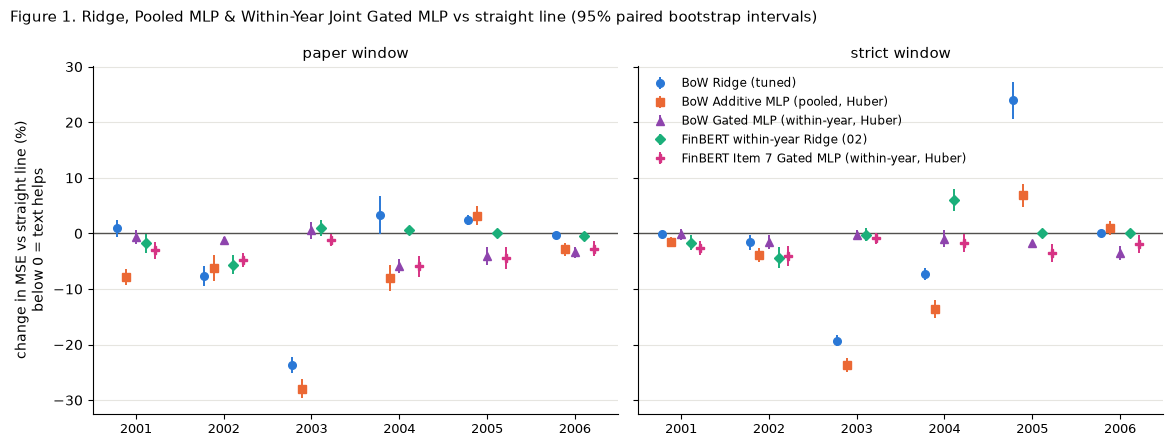

In [13]:
# Figure 1: Year-by-year comparison with 95% paired bootstrap intervals
COLORS = {
    "ridge: words + last year": "#2a78d6",
    ens_name("network: words + last year (Huber, refit)"): "#eb6834",
    ens_name("gated MLP (within-year): BoW + last year (Huber, refit)"): "#8e44ad",
    "within-year ridge, Item 7 (FinBERT, from 02)": "#1baf7a",
}
if X_FINBERT_DOC is not None:
    COLORS[ens_name("gated MLP (within-year): FinBERT Item 7 + last year (Huber, refit)")] = "#d63384"

MARKERS = dict(zip(COLORS, ["o", "s", "^", "D", "P"]))
OFFSET = dict(zip(COLORS, np.linspace(-0.22, 0.22, len(COLORS))))
LABELS = {
    "ridge: words + last year": "BoW Ridge (tuned)",
    ens_name("network: words + last year (Huber, refit)"): "BoW Additive MLP (pooled, Huber)",
    ens_name("gated MLP (within-year): BoW + last year (Huber, refit)"): "BoW Gated MLP (within-year, Huber)",
    "within-year ridge, Item 7 (FinBERT, from 02)": "FinBERT within-year Ridge (02)",
    ens_name("gated MLP (within-year): FinBERT Item 7 + last year (Huber, refit)"): "FinBERT Item 7 Gated MLP (within-year, Huber)",
}

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), sharey=True)
for ax, window in zip(axes, scoring.WINDOWS):
    ax.axhline(0, color="#52514e", lw=1)
    for name in COLORS:
        r = shown[(shown.model == name) & (shown.window == window)]
        if r.empty:
            continue
        pct, lo, hi = r.change_pct, 100 * r.ci_low / r.baseline_mse, 100 * r.ci_high / r.baseline_mse
        ax.errorbar(r.test_year + OFFSET[name], pct, yerr=[pct - lo, hi - pct],
                    fmt=MARKERS[name], color=COLORS[name], ms=5.5, lw=1.4, capsize=0, label=LABELS[name])
    ax.set_title(f"{window} window", fontsize=11)
    ax.set_xticks(list(scoring.TEST_YEARS))
    ax.tick_params(axis="x", labelsize=9)
    ax.grid(axis="y", color="#e6e5e0", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = text helps")
axes[-1].legend(frameon=False, loc="best", fontsize=8.5)
fig.suptitle("Figure 1. Ridge, Pooled MLP & Within-Year Joint Gated MLP vs straight line (95% paired bootstrap intervals)",
             fontsize=11, x=0.01, ha="left")
fig.tight_layout()
plt.show()

In [14]:
# Level vs. Spread decomposition (main window)
b_ = copy_vs_line[copy_vs_line.window == MAIN_WINDOW].set_index("test_year")
rows = {"line: level as % of its MSE": 100 * b_["baseline_level"] / b_["baseline_mse"]}
decomp_models = [
    "ridge: words + last year",
    ens_name("network: words + last year (Huber, refit)"),
    ens_name("network: within-year words + last year (refit)"),
    ens_name("gated MLP: BoW + last year (Huber, refit)"),
    ens_name("gated MLP (within-year): BoW + last year (Huber, refit)"),
]
if X_FINBERT_DOC is not None:
    decomp_models += [
        ens_name("network: FinBERT Item 7 + last year (Huber, refit)"),
        ens_name("gated MLP: FinBERT Item 7 + last year (Huber, refit)"),
        ens_name("network (within-year): FinBERT Item 7 + last year (Huber, refit)"),
        ens_name("gated MLP (within-year): FinBERT Item 7 + last year (Huber, refit)"),
    ]
if X_CHUNKS is not None:
    decomp_models.append(ens_name("attention-pool FinBERT chunks + gated MLP (Huber, refit)"))

for name in decomp_models:
    r = results[(results.model == name) & (results.window == MAIN_WINDOW)].set_index("test_year")
    rows[f"{name}: level"] = 100 * (r["level"] - r["baseline_level"]) / r["baseline_mse"]
    rows[f"{name}: spread"] = 100 * (r["spread"] - r["baseline_spread"]) / r["baseline_mse"]
pd.DataFrame(rows).T.round(1)

test_year,2001,2002,2003,2004,2005,2006
line: level as % of its MSE,29.9,4.4,44.3,8.4,0.1,1.0
ridge: words + last year: level,0.1,-4.4,-23.6,-6.0,1.9,0.1
ridge: words + last year: spread,0.9,-3.3,-0.0,9.3,0.5,-0.5
"network: words + last year (Huber, refit, 5 seeds averaged): level",-7.7,-3.8,-27.3,-8.4,3.6,-0.6
"network: words + last year (Huber, refit, 5 seeds averaged): spread",-0.1,-2.3,-0.6,0.4,-0.4,-2.2
"network: within-year words + last year (refit, 5 seeds averaged): level",-0.0,0.0,0.0,0.0,0.0,-0.0
"network: within-year words + last year (refit, 5 seeds averaged): spread",0.3,-2.7,1.9,0.4,0.0,-1.1
"gated MLP: BoW + last year (Huber, refit, 5 seeds averaged): level",-8.7,-1.5,-22.5,-8.2,0.8,-0.6
"gated MLP: BoW + last year (Huber, refit, 5 seeds averaged): spread",-0.8,-0.2,-0.4,-4.1,-2.7,-2.5
"gated MLP (within-year): BoW + last year (Huber, refit, 5 seeds averaged): level",0.0,0.0,0.0,-0.0,0.0,-0.0


In [15]:
# Takeover sensitivity table (evaluates 5-seed averaged ensembles directly)
def split_preds(window, T):
    train, test = (as_mask(m) for m in scoring.masks(df, T, window))
    p = dict(fit_split(train, test))
    a, b = scoring.fit_line(df, train)
    p["copy last year"], p["straight line"] = prev[test], a + b * prev[test]
    return y[test], p

rows = []
for window in scoring.WINDOWS:
    for T in scoring.TEST_YEARS:
        yt, p = split_preds(window, T)
        keep = yt >= VERY_LOW
        for name, pt in p.items():
            if ", seed " in name:
                continue
            rows.append({
                "window": window, "test_year": T, "model": name,
                "test_mse": mse(yt, pt),
                "test_mse_excl_takeovers": mse(yt[keep], pt[keep]),
                "takeover_share": 1 - keep.mean(),
            })

tk = (pd.DataFrame(rows).groupby(["window", "model"], sort=False)
      .agg(test_mse=("test_mse", "mean"),
           test_mse_excl_takeovers=("test_mse_excl_takeovers", "mean"),
           reports_dropped=("takeover_share", lambda s: f"{s.mean():.1%}")))
tk.round(3)

test_mse  \
window model                                                          
paper  train mean                                             0.399   
       ridge: words only                                      0.159   
       ridge: words + last year                               0.119   
       network: words only (refit, 5 seeds averaged)          0.153   
       network: words + last year (no refit, 5 seeds a...     0.120   
       network: words + last year (refit, 5 seeds aver...     0.116   
       network: words + last year (Huber, refit, 5 see...     0.114   
       network: within-year words + last year (refit, ...     0.127   
       gated MLP: BoW + last year (Huber, refit, 5 see...     0.114   
       gated MLP (within-year): BoW + last year (Huber...     0.125   
       network: FinBERT Item 7 + last year (refit, 5 s...     0.119   
       network: FinBERT Item 7 + last year (Huber, ref...     0.116   
       gated MLP: FinBERT Item 7 + last year (Huber, r...     0.117   
       network (within-year): FinBERT Item 7 + last ye...     0.122   
       gated MLP (within-year): FinBERT Item 7 + last ...     0.123   
       copy last year                                         0.124   
       straight line                                          0.127   
strict train mean                                             0.442   
       ridge: words only                                      0.214   
       ridge: words + last year                               0.129   
       network: words only (refit, 5 seeds averaged)          0.214   
       network: words + last year (no refit, 5 seeds a...     0.139   
       network: words + last year (refit, 5 seeds aver...     0.127   
       network: words + last year (Huber, refit, 5 see...     0.123   
       network: within-year words + last year (refit, ...     0.133   
       gated MLP: BoW + last year (Huber, refit, 5 see...     0.125   
       gated MLP (within-year): BoW + last year (Huber...     0.132   
       network: FinBERT Item 7 + last year (refit, 5 s...     0.129   
       network: FinBERT Item 7 + last year (Huber, ref...     0.126   
       gated MLP: FinBERT Item 7 + last year (Huber, r...     0.128   
       network (within-year): FinBERT Item 7 + last ye...     0.130   
       gated MLP (within-year): FinBERT Item 7 + last ...     0.130   
       copy last year                                         0.124   
       straight line                                          0.133   

                                                           test_mse_excl_takeovers  \
window model                                                                         
paper  train mean                                                            0.381   
       ridge: words only                                                     0.144   
       ridge: words + last year                                              0.105   
       network: words only (refit, 5 seeds averaged)                         0.138   
       network: words + last year (no refit, 5 seeds a...                    0.106   
       network: words + last year (refit, 5 seeds aver...                    0.102   
       network: words + last year (Huber, refit, 5 see...                    0.100   
       network: within-year words + last year (refit, ...                    0.112   
       gated MLP: BoW + last year (Huber, refit, 5 see...                    0.100   
       gated MLP (within-year): BoW + last year (Huber...                    0.110   
       network: FinBERT Item 7 + last year (refit, 5 s...                    0.104   
       network: FinBERT Item 7 + last year (Huber, ref...                    0.102   
       gated MLP: FinBERT Item 7 + last year (Huber, r...                    0.102   
       network (within-year): FinBERT Item 7 + last ye...                    0.107   
       gated MLP (within-year): FinBERT Item 7 + last ...                    0.108   
       copy last year                   

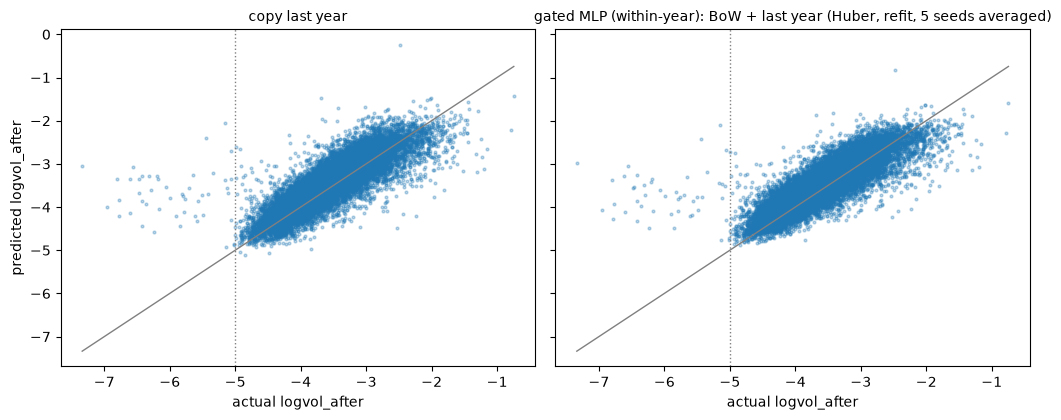

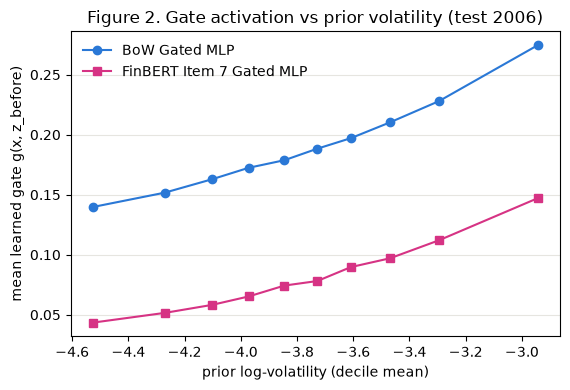

In [16]:
# Interpretability: (1) Predicted vs Actual Scatter, (2) Learned Gate vs Prior Volatility (+ Chunk Attention)
T_LAST = max(scoring.TEST_YEARS)
D_last = DIAGNOSTICS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
te_idx = D_last["te_idx"]
prev_te = prev[te_idx]

parts = [split_preds(MAIN_WINDOW, T) for T in scoring.TEST_YEARS]
yt = np.concatenate([p[0] for p in parts])
best_gated_name = ens_name("gated MLP (within-year): BoW + last year (Huber, refit)")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), sharex=True, sharey=True)
for ax, name in zip(axes, ["copy last year", best_gated_name]):
    ax.scatter(yt, np.concatenate([p[1][name] for p in parts]), s=4, alpha=0.3)
    lims = [yt.min(), yt.max()]
    ax.plot(lims, lims, color="grey", lw=1)
    ax.axvline(VERY_LOW, color="grey", ls=":", lw=1)
    ax.set_xlabel("actual logvol_after")
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("predicted logvol_after")
plt.tight_layout()
plt.show()

n_plots = 2 if "attn_weights_mean" in D_last else 1
fig, axes = plt.subplots(1, n_plots, figsize=(5.8 * n_plots, 4.0))
if n_plots == 1:
    axes = [axes]

deciles = pd.qcut(prev_te, q=10)
g_df = pd.DataFrame({"prev_logvol": prev_te, "bow_gate": D_last["bow_gate_mean"], "decile": deciles})
g_bow = g_df.groupby("decile", observed=False).agg(prev_mean=("prev_logvol", "mean"), gate_mean=("bow_gate", "mean"))
axes[0].plot(g_bow["prev_mean"], g_bow["gate_mean"], "o-", color="#2a78d6", label="BoW Gated MLP")
if "fb_gate_mean" in D_last:
    g_df["fb_gate"] = D_last["fb_gate_mean"]
    g_fb = g_df.groupby("decile", observed=False).agg(prev_mean=("prev_logvol", "mean"), gate_mean=("fb_gate", "mean"))
    axes[0].plot(g_fb["prev_mean"], g_fb["gate_mean"], "s-", color="#d63384", label="FinBERT Item 7 Gated MLP")
axes[0].set_xlabel("prior log-volatility (decile mean)")
axes[0].set_ylabel("mean learned gate g(x, z_before)")
axes[0].set_title(f"Figure 2. Gate activation vs prior volatility (test {T_LAST})")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", color="#e6e5e0", lw=0.8)

if "attn_weights_mean" in D_last:
    w_a = D_last["attn_weights_mean"]
    n_valid = CHUNK_MASK[te_idx].sum(axis=1)
    ratio = w_a.max(axis=1) / (1.0 / np.maximum(n_valid, 1))
    axes[1].hist(ratio[n_valid >= 2], bins=30, color="#1baf7a", alpha=0.8)
    axes[1].axvline(1.0, color="#52514e", ls="--", lw=1.2, label="uniform mean-pool (ratio = 1)")
    axes[1].set_xlabel("max attention weight / uniform (1 / M_i)")
    axes[1].set_ylabel("number of reports (M_i >= 2 chunks)")
    axes[1].set_title(f"Chunk attention focus (median ratio = {np.median(ratio[n_valid >= 2]):.2f}x)")
    axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

In [17]:
# 5-Seed Ensemble Word Attribution (Gradient x Input) vs Ridge Coefficients
M = MODELS[KEY_OF[(MAIN_WINDOW, T_LAST)]]
S_last = make_split(*scoring.masks(df, T_LAST, MAIN_WINDOW))
assert (S_last.cols_full == M["cols"]).all(), "features were rebuilt differently from the fit"
words = vocab[M["cols"]]
word_index = {w: j for j, w in enumerate(words)}
print(f"window {MAIN_WINDOW}, test year {T_LAST}: train {KEY_OF[(MAIN_WINDOW, T_LAST)][0][0]}-{KEY_OF[(MAIN_WINDOW, T_LAST)][0][-1]}")

coef = M["ridge_text"].coef_
order_ = np.argsort(coef)
print("ridge, words only -- push volatility DOWN:", words[order_[:15]].tolist())
print("ridge, words only -- push volatility UP:  ", words[order_[::-1][:15]].tolist())

rng = np.random.default_rng(0)
sample = rng.choice(S_last.te_idx, size=min(2000, len(S_last.te_idx)), replace=False)
X_last_t = to_dense_tensor(S_last.X_full)
prev_last_t = torch.from_numpy(S_last.prev_z_full).to(device)
attr = np.zeros(S_last.X_full.shape[1])

for model in M["nets"]:
    model.eval()
    for i in range(0, len(sample), 500):
        r = sample[i:i + 500]
        model.zero_grad(set_to_none=True)
        xb = X_last_t[S_last.pos_full[r]].clone().detach().requires_grad_(True)
        model(xb, prev_last_t[r]).sum().backward()
        attr += (xb.grad * xb).sum(dim=0).detach().cpu().numpy()

attr /= (len(sample) * len(M["nets"]))
order_ = np.argsort(attr)
print(f"\nnetwork ({len(SEEDS)}-seed refit ensemble), words + last year -- push prediction DOWN:", words[order_[:15]].tolist())
print(f"network ({len(SEEDS)}-seed refit ensemble), words + last year -- push prediction UP:  ", words[order_[::-1][:15]].tolist())
del X_last_t
gc.collect()

window paper, test year 2006: train 2001-2005
ridge, words only -- push volatility DOWN: ['sharebased', 'dividends', 'esop', 'unsecured', 'policies', 'regulated', 'ferc', 'acquisitions', 'repurchase', 'timing', 'warmer', 'largely', 'distributions', 'coal', 'acquire']
ridge, words only -- push volatility UP:   ['loss', 'nasdaq', 'doubt', 'concern', 'raise', 'financing', 'debenture', 'going', 'smallcap', 'extraordinary', 'reciprocal', 'longlived', 'managements', 'personnel', 'default']

network (5-seed refit ensemble), words + last year -- push prediction DOWN: ['contents', 'stockbased', 'improved', 'billion', 'repurchase', 'rate', 'corrections', 'earnings', 'eitf', 'contributed', 'gains', 'disclosure', 'table', 'previously', 'returns']
network (5-seed refit ensemble), words + last year -- push prediction UP:   ['sharebased', 'sarbanesoxley', 'loss', 'longlived', 'lease', 'fsp', 'vesting', 'impairment', 'financing', 'sfas', 'supersedes', 'administrative', 'awards', 'payment', 'prices']


7643

## 5.9 — Computational Cost, Parallelism, Hashing & the 1,000× Scaling Question

Benchmarks four dimensions for a 1,000× production deployment (~27M reports):
1. **Learning curve & data-volume scaling** (`10%, 25%, 50%, 100%` of `S_last.fit_idx`).
2. **Batching bottleneck (sparse-per-batch vs. pre-dense)** and **CPU strong scaling** (`1, 2, 4, 8` threads).
3. **Stateless Map-only `HashingVectorizer` vs. Map-Reduce `CountVectorizer + TF-IDF`** on `T_LAST` texts.
4. **1,000× back-of-envelope extrapolation** for memory, tokenization, and training epochs.

Batching speedup (pre-dense vs sparse-per-batch): 0.167s -> 0.104s (1.60x faster)
Vectorization on 3,003 reports (2006): Map-Reduce TF-IDF 11.54s vs Map-only Hashing 9.78s


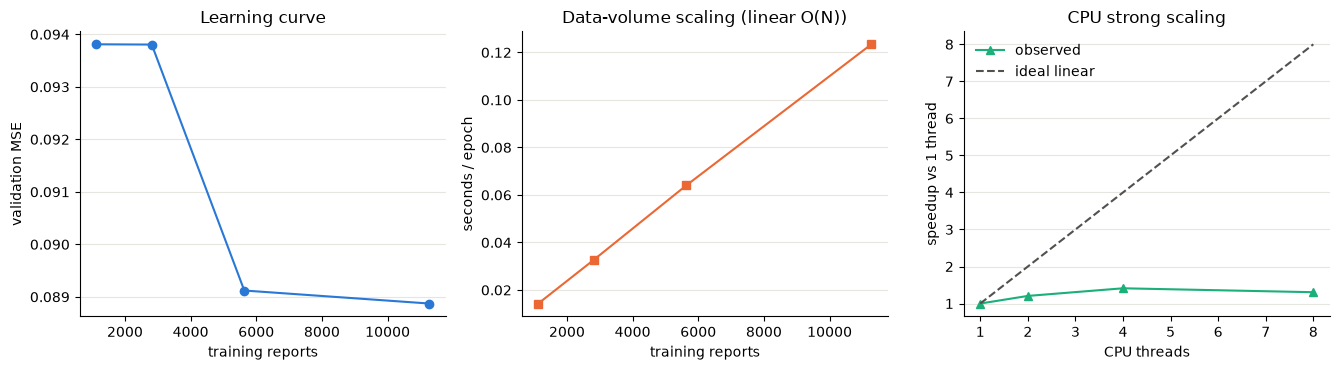

,metric,current (1x),"scaled (1,000x)"
0,Reports,"27,142","27,142,000"
1,Dense float32 BoW matrix,0.51 GB,506 GB (infeasible in RAM)
2,Sparse CSR BoW matrix,0.193 GB,192.5 GB (shardable)
3,Tokenization (1 core),91.2 s,25.3 hrs (~0.40 hrs on 64 cores)
4,1 training epoch (single CPU node),0.10 s,0.07 hrs (streaming/GPU cluster needed)


8976

In [18]:
# 1. Batching bottleneck: sparse-per-batch vs pre-dense (3 epochs on S_last.fit_idx)
X_fit_sp = S_last.X_tune[S_last.pos_tune[S_last.fit_idx]]
X_fit_t = to_dense_tensor(S_last.X_tune)
y_fit_t = torch.from_numpy(S_last.y_z_fit).to(device)
prev_fit_t = torch.from_numpy(S_last.prev_z_fit).to(device)

def bench_sparse_epoch(n_epochs=3):
    torch.manual_seed(0)
    rng = np.random.default_rng(0)
    m = ResidualTextNet(X_fit_sp.shape[1], HIDDEN, DROPOUT, True).to(device)
    opt = make_optimizer(m, LR, WEIGHT_DECAY)
    loss_fn = nn.MSELoss()
    t0 = time.perf_counter()
    for _ in range(n_epochs):
        perm = rng.permutation(len(S_last.fit_idx))
        for i in range(0, len(perm), BATCH):
            p_idx = perm[i:i + BATCH]
            r = S_last.fit_idx[p_idx]
            opt.zero_grad(set_to_none=True)
            xb = torch.from_numpy(X_fit_sp[p_idx].toarray()).to(device)
            loss = loss_fn(m(xb, prev_fit_t[r]), y_fit_t[r])
            loss.backward()
            opt.step()
    return (time.perf_counter() - t0) / n_epochs

def bench_dense_epoch(n_epochs=3):
    torch.manual_seed(0)
    rng = np.random.default_rng(0)
    m = ResidualTextNet(X_fit_t.shape[1], HIDDEN, DROPOUT, True).to(device)
    opt = make_optimizer(m, LR, WEIGHT_DECAY)
    loss_fn = nn.MSELoss()
    t0 = time.perf_counter()
    for _ in range(n_epochs):
        perm = rng.permutation(S_last.fit_idx)
        for i in range(0, len(perm), BATCH):
            r = perm[i:i + BATCH]
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(m(X_fit_t[S_last.pos_tune[r]], prev_fit_t[r]), y_fit_t[r])
            loss.backward()
            opt.step()
    return (time.perf_counter() - t0) / n_epochs

t_sparse = bench_sparse_epoch()
t_dense = bench_dense_epoch()
print(f"Batching speedup (pre-dense vs sparse-per-batch): {t_sparse:.3f}s -> {t_dense:.3f}s ({t_sparse / t_dense:.2f}x faster)")

# 2. Learning curve & data-volume scaling (10%, 25%, 50%, 100% of S_last.fit_idx)
lc_rows = []
rng_lc = np.random.default_rng(42)
for frac in [0.10, 0.25, 0.50, 1.00]:
    n_sub = max(BATCH, int(len(S_last.fit_idx) * frac))
    sub_idx = rng_lc.choice(S_last.fit_idx, size=n_sub, replace=False) if frac < 1.0 else S_last.fit_idx
    m_sub, h_sub, bep = train_nn_fast(
        X_fit_t, S_last.pos_tune, y_fit_t, prev_fit_t, sub_idx, S_last.val_idx, S_last.sd_fit,
        use_prev=True, gated=False, seed=0, hidden=HIDDEN, dropout=DROPOUT, weight_decay=WEIGHT_DECAY,
        loss_type="huber", huber_delta=HUBER_DELTA, use_val=True,
    )
    lc_rows.append({
        "fraction": frac, "n_reports": n_sub,
        "val_mse": float(h_sub["val_mse"].min()),
        "sec_per_epoch": float(h_sub["seconds"].mean()),
    })
lc_df = pd.DataFrame(lc_rows)

# 3. CPU strong scaling (1, 2, 4, 8 threads)
orig_threads = torch.get_num_threads()
max_t = min(8, os.cpu_count() or 1)
thread_list = [t for t in [1, 2, 4, 8] if t <= max_t]
th_rows = []
for n_th in thread_list:
    torch.set_num_threads(n_th)
    sec = bench_dense_epoch(n_epochs=3)
    th_rows.append({"threads": n_th, "sec_per_epoch": sec})
torch.set_num_threads(orig_threads)
th_df = pd.DataFrame(th_rows)
th_df["speedup"] = th_df["sec_per_epoch"].iloc[0] / th_df["sec_per_epoch"]

# 4. Map-only HashingVectorizer vs Map-Reduce CountVectorizer + TF-IDF on T_LAST texts
t_last_texts = load_year_texts(T_LAST)
t0 = time.perf_counter()
cv = CountVectorizer(min_df=5, stop_words="english", token_pattern=TOKEN, max_features=N_WORDS)
X_cv = TfidfTransformer(sublinear_tf=True).fit_transform(cv.fit_transform(t_last_texts))
t_mr = time.perf_counter() - t0

t0 = time.perf_counter()
hv = HashingVectorizer(n_features=N_WORDS, stop_words="english", token_pattern=TOKEN, alternate_sign=False)
X_hv = hv.transform(t_last_texts)
t_map = time.perf_counter() - t0
print(f"Vectorization on {len(t_last_texts):,} reports ({T_LAST}): Map-Reduce TF-IDF {t_mr:.2f}s vs Map-only Hashing {t_map:.2f}s")

# Plot scaling diagnostics
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
axes[0].plot(lc_df["n_reports"], lc_df["val_mse"], "o-", color="#2a78d6")
axes[0].set_xlabel("training reports")
axes[0].set_ylabel("validation MSE")
axes[0].set_title("Learning curve")
axes[0].grid(axis="y", color="#e6e5e0", lw=0.8)

axes[1].plot(lc_df["n_reports"], lc_df["sec_per_epoch"], "s-", color="#eb6834")
axes[1].set_xlabel("training reports")
axes[1].set_ylabel("seconds / epoch")
axes[1].set_title("Data-volume scaling (linear O(N))")
axes[1].grid(axis="y", color="#e6e5e0", lw=0.8)

axes[2].plot(th_df["threads"], th_df["speedup"], "^-", color="#1baf7a", label="observed")
axes[2].plot(th_df["threads"], th_df["threads"], "--", color="#52514e", label="ideal linear")
axes[2].set_xlabel("CPU threads")
axes[2].set_ylabel("speedup vs 1 thread")
axes[2].set_title("CPU strong scaling")
axes[2].legend(frameon=False)
axes[2].grid(axis="y", color="#e6e5e0", lw=0.8)

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

# 1,000x back-of-envelope extrapolation (~27M reports)
scale_factor = 1000
n_27m = len(df) * scale_factor
dense_gb_27m = (n_27m * N_WORDS * 4) / (1024 ** 3)
nnz_per_doc = X_fit_sp.nnz / X_fit_sp.shape[0]
sparse_gb_27m = (n_27m * nnz_per_doc * 8) / (1024 ** 3)
tok_hours_1core = (timings["count_seconds"] * scale_factor) / 3600
epoch_hours_1node = (t_dense * (n_27m / len(S_last.fit_idx))) / 3600

extrap = pd.DataFrame([
    {"metric": "Reports", "current (1x)": f"{len(df):,}", "scaled (1,000x)": f"{n_27m:,}"},
    {"metric": "Dense float32 BoW matrix", "current (1x)": f"{dense_gb_27m / 1000:.2f} GB", "scaled (1,000x)": f"{dense_gb_27m:,.0f} GB (infeasible in RAM)"},
    {"metric": "Sparse CSR BoW matrix", "current (1x)": f"{sparse_gb_27m / 1000:.3f} GB", "scaled (1,000x)": f"{sparse_gb_27m:,.1f} GB (shardable)"},
    {"metric": "Tokenization (1 core)", "current (1x)": f"{timings['count_seconds']:.1f} s", "scaled (1,000x)": f"{tok_hours_1core:.1f} hrs (~{tok_hours_1core / 64:.2f} hrs on 64 cores)"},
    {"metric": "1 training epoch (single CPU node)", "current (1x)": f"{t_dense:.2f} s", "scaled (1,000x)": f"{epoch_hours_1node:.2f} hrs (streaming/GPU cluster needed)"},
])
display(extrap)
del X_fit_t
gc.collect()